# 04_followup_fix_pilot.ipynb — Detach-Hydra fix pilot: more averaging (Fix A) and a hybrid budget (Fix D)

**Author:** Shreed

**Notebook:** `02_detach_hydra/notebooks/04_followup_fix_pilot.ipynb`. It follows `02_development_run.ipynb` and `03_heldout_confirmation.ipynb`.

## Background, in plain words

**Detach-Hydra** trains the full Hydra (k = 8, g = 64) and then removes whole kernel groups, keeping a fixed fraction (the *budget*) of them.
- **Detach v1** scores each group by the size of its ridge weights, fitted on the whole training set, and repeatedly removes the weakest 10 %.
- **Detach v2** does the same, but averages the scores over 5 fixed stratified subsamples, each 80 % of the training set.

**The problem: the ranking overfits.** The same training data is used to fit the classifier and to judge the groups, so a group that happens to fit noise looks important.
- On MiddlePhalanxOutlineAgeGroup, v1 lost about 11 pp against a fresh smaller Hydra (`small_g`), and v2 still lost 7–8.5 pp.
- While pruning, the training score kept improving as test accuracy fell.

## The two fixes piloted here

- **Fix A, more averaging (`detach_v2A`).** Score over **20 subsamples of 50 %** instead of 5 of 80 %. Five 80 % portions overlap heavily, so their classifiers see almost the same data and make the same mistakes. Many different halves make a noise-fitting group look important only occasionally, so its average score drops. It is the *same* path function as v2, called with `B = 20, frac = 0.5`.
- **Fix D, hybrid budget (`detach_v2_hybrid`).** At each budget, fill **half** the groups from the global ranking, and spread the **other half evenly** over every (dilation, input) block. If the ranking is wrong, the even half limits the damage. On MiddlePhalanxOutlineAgeGroup the even-coverage variant (`detach_stratified` in the decisive notebook) scored 0.661 against 0.599 for global Detach at 1/16.
- **A + D (`detach_v2A_hybrid`).** The hybrid selection built on the Fix A ranking.

## Pilot data

The 6 **development** datasets of the confirm notebook's Stage A, 5 splits each:
- **failures** (v1's worst): MiddlePhalanxOutlineAgeGroup, Worms, ScreenType;
- **winners** (v1's best): WordSynonyms, FiftyWords, Herring.

A fix that repairs the failures but destroys the wins is no use, so both groups are reported side by side. **No held-out dataset is used** (asserted in the settings).

## Run guide

| Setting | Meaning |
|---|---|
| `QUICK_RUN = False` | the real pilot: 6 datasets × 5 splits |
| `QUICK_RUN = True` | smoke test: MiddlePhalanxOutlineAgeGroup × resample 0; every output file is prefixed `quick_` |
| `EXTRA_DEV_DATASETS` | optional further **development** datasets for a broader second look (default `[]`) |

**Order of the notebook:** settings → reused code → the new hybrid function → checks (the notebook stops if any fails) → the checkpointed experiment → the reproducibility check against earlier runs → comparison tables and figures.

**Outputs** (in `02_detach_hydra/results/`): `detach_fix_pilot_runs.csv`, `detach_fix_pilot_paths.csv`, `detach_fix_pilot_rankings.csv`, `detach_fix_pilot_kept_groups.csv`, `detach_fix_pilot_failures.csv` (only if something fails), and figures prefixed `detach_fix_pilot_` (in `02_detach_hydra/results/figures/`).

**Resuming.** Rows are appended after every (dataset, resample) pair, with `runs` written last as the completion marker. Re-running the notebook skips completed pairs.

**Expected runtime** on the same Mac: roughly 11–15 min. Stage A (full + v1 + v2 + `small_g` on these 6 datasets) took 8.9 min, most of it the `small_g` transforms; the paths took only about 1.6 min in total. Fix A adds one path with 20 smaller ridge fits per step instead of 5, so about 1.5–4× the v2 path time (about 2–5 extra min), and the hybrids add only final ridge fits.

**Headless run** (from the repo root; needs `nbconvert` in `hydra_env`, see the confirm notebook's run guide):

```
nohup caffeinate -i hydra_env/bin/jupyter nbconvert --to notebook --execute --inplace \
    --ExecutePreprocessor.timeout=-1 02_detach_hydra/notebooks/04_followup_fix_pilot.ipynb \
    > 02_detach_hydra/results/detach_fix_pilot_log.txt 2>&1 &
```

## 1. Setup

In [1]:
from pathlib import Path
import sys

# Repository root = the folder that contains hydra-authors-repo/ (works from any working directory)
ROOT = Path.cwd().resolve()
while not (ROOT / "hydra-authors-repo").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the hydra-time-series-project repository.")
    ROOT = ROOT.parent

HYDRA_CODE  = ROOT / "hydra-authors-repo" / "code"
AUTHORS_RES = ROOT / "hydra-authors-repo" / "results"
RESULTS_DIR = ROOT / "02_detach_hydra" / "results"
FIG_DIR     = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HYDRA_CODE))

PROJECT_DIR = ROOT
DATA_DIR = ROOT / "data" / "ucr_tsml"          # git-ignored; aeon downloads any missing dataset here
# read only; written by 01_reproduction/notebooks/01_hydra_baseline.ipynb (run that first)
BASELINE_CSV = ROOT / "01_reproduction" / "results" / "hydra_default_baseline.csv"
print("Project directory:", PROJECT_DIR.resolve())

Project directory: /Users/shreed/PROJECTS/Hydra_1


In [2]:
import gc
import importlib.util
import inspect
import json
import math
import os
import random
import sys
import traceback
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import wilcoxon

from aeon.datasets import load_classification
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

# sklearn's LinAlgWarning: ridge at a small alpha with n_train << n_features gives a near-singular Gram matrix.
# sklearn warns and falls back to a least-squares solve. These are warnings, not errors; the results are still
# computed (the same filter as the decisive notebook). Filtering them keeps the progress log readable.
from scipy.linalg import LinAlgWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="Singular matrix in solving dual problem")
warnings.filterwarnings("ignore", message="The least populated class")

print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__)

numpy 2.3.5 | pandas 3.0.6 | torch 2.15.0


### Settings

- **Same splits, kernels, budgets and seeds as the decisive and Stage A runs**, so every earlier number can be reproduced exactly (Check 8).
- **v2A seeds** `20_000 + 100·r + b` (b = 1..20) never collide with v2's `10_000 + 100·r + b`.
- The dataset lists are asserted to be development datasets only.

In [3]:
# ===================== settings =====================
QUICK_RUN = False            # True: 1 dataset x 1 resample smoke test, outputs prefixed quick_. False for the pilot.

# The 40 development datasets, EXACTLY as in 02_development_run.ipynb
DEV_DATASETS = [
    "Beef", "BirdChicken", "Car", "CricketX", "CricketY", "CricketZ", "DistalPhalanxTW", "ECG5000",
    "FiftyWords", "Fish", "FordA", "FordB", "Haptics", "Herring", "InsectWingbeatSound",
    "ItalyPowerDemand", "LargeKitchenAppliances", "Lightning7", "Meat", "MedicalImages",
    "MiddlePhalanxOutlineAgeGroup", "MiddlePhalanxOutlineCorrect", "OSULeaf", "OliveOil", "Phoneme",
    "Plane", "ProximalPhalanxOutlineCorrect", "ProximalPhalanxTW", "ScreenType", "ShapeletSim",
    "Strawberry", "SwedishLeaf", "SyntheticControl", "ToeSegmentation1", "Trace",
    "UWaveGestureLibraryY", "Wafer", "WordSynonyms", "Worms", "Yoga",
]
assert len(DEV_DATASETS) == 40 and len(set(DEV_DATASETS)) == 40, "need 40 unique development datasets"

# Held-out = all 112 datasets of the authors' UCR results file minus the 40 development datasets (never used here)
AUTHORS_UCR112_CSV = AUTHORS_RES / "results_ucr112_hydra.csv"     # read only
UCR112 = sorted(pd.read_csv(AUTHORS_UCR112_CSV)["dataset"].astype(str).unique())
assert len(UCR112) == 112, f"expected 112 unique datasets in {AUTHORS_UCR112_CSV.name}, got {len(UCR112)}"
HELDOUT_ALL = sorted(set(UCR112) - set(DEV_DATASETS))
assert len(HELDOUT_ALL) == 72

PILOT_FAILURES = ["MiddlePhalanxOutlineAgeGroup", "Worms", "ScreenType"]   # v1's worst (Stage A)
PILOT_WINNERS = ["WordSynonyms", "FiftyWords", "Herring"]                  # v1's best (Stage A)
PILOT_DATASETS = PILOT_FAILURES + PILOT_WINNERS
EXTRA_DEV_DATASETS = []      # optional further DEVELOPMENT datasets (a broader second look); never held-out ones

# Check 1 (dataset lists): development datasets only, none held out
for _ds in PILOT_DATASETS + EXTRA_DEV_DATASETS:
    assert _ds in DEV_DATASETS, f"{_ds} is not one of the 40 development datasets"
    assert _ds not in HELDOUT_ALL, f"{_ds} is a held-out dataset"
assert not {"Earthquakes", "DistalPhalanxOutlineAgeGroup"} & set(PILOT_DATASETS + EXTRA_DEV_DATASETS)
assert len(set(PILOT_DATASETS + EXTRA_DEV_DATASETS)) == len(PILOT_DATASETS + EXTRA_DEV_DATASETS), "duplicate dataset"
GROUP_OF = {**{d: "failure" for d in PILOT_FAILURES}, **{d: "winner" for d in PILOT_WINNERS},
            **{d: "extra" for d in EXTRA_DEV_DATASETS}}

RUN_DATASETS = ["MiddlePhalanxOutlineAgeGroup"] if QUICK_RUN else PILOT_DATASETS + EXTRA_DEV_DATASETS
RESAMPLES = [0] if QUICK_RUN else [0, 1, 2, 3, 4]          # 0 = default split; full-Hydra kernel seed = resample id

K = 8
G = 64                                                    # full Hydra g (groups per dilation)
BUDGETS = [0.5, 0.25, 0.125, 0.0625]                      # fraction of groups kept
SMALL_G = {0.5: 32, 0.25: 16, 0.125: 8, 0.0625: 4}         # matched fresh-Hydra g'
ALPHAS = np.logspace(-6, 6, 25)                           # every ridge fit (same as the decisive and confirm runs)
AUTHOR_ALPHAS = np.logspace(-3, 3, 10)                    # authors' grid: only for the ECG200 baseline check
PRUNE_FRACTION = 0.10                                     # remove 10% of active groups per step (every path)
V2_B = 5                                                  # Detach v2 (reference): number of stratified subsamples
SUBSAMPLE_FRAC = 0.8                                      # Detach v2 (reference): fraction of each class per subsample
B_A = 20                                                  # Fix A (v2A): number of stratified subsamples
FRAC_A = 0.5                                              # Fix A (v2A): fraction of each class per subsample
N_SMALLG_SEEDS = 3                                        # small_g seeds: 1000 + 10*resample_id + i
DRAW_TOL = 0.0005                                         # |delta acc| below this (0.05 pp) counts as a draw
N_BOOT = 10_000                                           # (used by the verbatim compare(); no tests are run here)
BATCH_SIZE = 256


def smallg_seed(resample_id, i):
    return 1000 + 10 * resample_id + i


def v2_seed_base(resample_id):
    return 10_000 + 100 * resample_id                      # subsample b (1..B) uses seed_base + b



def v2a_seed_base(resample_id):
    return 20_000 + 100 * resample_id                      # Fix A: subsample b (1..B_A) uses seed_base + b


N_THREADS = os.cpu_count()
torch.set_num_threads(N_THREADS)                          # all CPU threads

PREFIX = "quick_" if QUICK_RUN else ""
TAG = f"{PREFIX}detach_fix_pilot"
RUNS_CSV = RESULTS_DIR / f"{TAG}_runs.csv"
PATHS_CSV = RESULTS_DIR / f"{TAG}_paths.csv"
RANKINGS_CSV = RESULTS_DIR / f"{TAG}_rankings.csv"
KEPT_CSV = RESULTS_DIR / f"{TAG}_kept_groups.csv"
FAIL_CSV = RESULTS_DIR / f"{TAG}_failures.csv"
FIG_PREFIX = f"{TAG}_"

# Earlier results, READ ONLY (Check 8 and the spotlight table)
DECISIVE_RUNS_CSV = RESULTS_DIR / "detach_decisive_runs.csv"            # full, small_g, detach (= v1), detach_stratified
DEVCHECK_RUNS_CSV = RESULTS_DIR / "detach_confirm_devcheck_runs.csv"    # Stage A: full, detach_v1, detach_v2, small_g
assert DECISIVE_RUNS_CSV.exists() and DEVCHECK_RUNS_CSV.exists()

PRUNED_METHODS = ["detach_v1", "detach_v2", "detach_v2_hybrid", "detach_v2A", "detach_v2A_hybrid"]
FIXES = ["detach_v2A", "detach_v2_hybrid", "detach_v2A_hybrid"]           # each compared with detach_v2

CHECKS = []


def log_check(name, result="PASS"):
    CHECKS.append((name, result))
    print(f"CHECK {result}: {name}")


def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)



log_check(f"Check 1: dataset lists - {len(PILOT_DATASETS + EXTRA_DEV_DATASETS)} datasets, all development, none held out")
print(f"QUICK_RUN={QUICK_RUN} | datasets {RUN_DATASETS} | resamples {RESAMPLES} | threads {N_THREADS}")
print("outputs:", RUNS_CSV.name, PATHS_CSV.name, RANKINGS_CSV.name, KEPT_CSV.name, FAIL_CSV.name)

CHECK PASS: Check 1: dataset lists - 6 datasets, all development, none held out
QUICK_RUN=False | datasets ['MiddlePhalanxOutlineAgeGroup', 'Worms', 'ScreenType', 'WordSynonyms', 'FiftyWords', 'Herring'] | resamples [0, 1, 2, 3, 4] | threads 10
outputs: detach_fix_pilot_runs.csv detach_fix_pilot_paths.csv detach_fix_pilot_rankings.csv detach_fix_pilot_kept_groups.csv detach_fix_pilot_failures.csv


In [4]:
# Import the authors' Hydra BY FILE PATH (pip `hydra-core` would shadow `import hydra`). Not modified.
HYDRA_SOURCE = HYDRA_CODE / "hydra.py"
assert HYDRA_SOURCE.exists(), f"Missing official implementation: {HYDRA_SOURCE}"
spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)
Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler

# Confirm the group arithmetic used for budget matching: divisor = 2, h = g // 2, groups = num_dilations * g
for L_ in [24, 96, 500, 1024]:
    for g_ in [64, 32, 16, 8, 4]:
        hy_ = Hydra(L_, k=K, g=g_, seed=0)
        assert hy_.divisor == 2 and hy_.h == g_ // 2
        assert hy_.W.shape == (hy_.num_dilations, 2, K * hy_.h, 1, 9)
        assert hy_.num_dilations * hy_.divisor * hy_.h == hy_.num_dilations * g_
    assert Hydra(L_, g=4, seed=0).num_dilations == Hydra(L_, g=64, seed=0).num_dilations   # same dilations
log_check("official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g")

CHECK PASS: official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g


### Reused, verified code

No `detach_hydra_v2_utils.py` or `detach_hydra_utils.py` exists, so the verified functions are copied verbatim into the cells below. Nothing in these three cells is changed.

| Cell below | Copied from | What |
|---|---|---|
| Reused from `02_development_run.ipynb`, cell 8 | identical to the confirm notebook's cell 10 | `load_ucr_dataset`, `make_split` (stratified resampling), `to_tensor` |
| Reused from `02_development_run.ipynb`, cell 9 | identical to the confirm notebook's cell 11 | `group_feature_index`, `kept_columns`, `group_table`, `PrunedHydra`, `transform`, `assert_same`, … |
| Reused from `03_heldout_confirmation.ipynb`, cell 12 | itself verbatim from the decisive notebook's cells 17, 18, 20 and 25 | `alpha_at_edge`, **v1 path** `detach_path` (per-step alpha re-selection, `np.atleast_2d(coef_)`, budget clamping, full ranking `order`), `block_counts`, `fit_ridge`, `holm`, `compare`, `drop_incomplete`, `append_csv` |

The settings cell also copies the 40-name `DEV_DATASETS` list, `smallg_seed`, `v2_seed_base`, `log_check` and `set_seeds` from the confirm notebook's cell 7, and the Hydra import cell is the confirm notebook's cell 8.

In [5]:
# ==== Reused from 02_development_run.ipynb, cell 8 (unchanged) ====
# ---- Data loading (same checks as 01_reproduction/notebooks/01_hydra_baseline.ipynb) and stratified resampling ----
def load_ucr_dataset(dataset_name, extract_path=DATA_DIR):
    X_train, y_train = load_classification(
        name=dataset_name, split="train", extract_path=str(extract_path), return_metadata=False
    )
    X_test, y_test = load_classification(
        name=dataset_name, split="test", extract_path=str(extract_path), return_metadata=False
    )
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)

    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError(f"{dataset_name}: expected 3D arrays")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(f"{dataset_name}: expected univariate data")
    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(f"{dataset_name}: train/test lengths differ")
    if not set(np.unique(y_test)).issubset(set(np.unique(y_train))):
        raise ValueError(f"{dataset_name}: test labels include unseen classes")
    return X_train, y_train, X_test, y_test


def make_split(X_train, y_train, X_test, y_test, resample_id):
    # resample 0 = default UCR split. Otherwise pool train+test and draw a new train set with the
    # SAME per-class counts as the original train set (seeded by resample_id); the rest is the test set.
    if resample_id == 0:
        return X_train, y_train, X_test, y_test
    X = np.concatenate([X_train, X_test])
    y = np.concatenate([y_train, y_test])
    rng = np.random.RandomState(resample_id)
    classes, counts = np.unique(y_train, return_counts=True)
    train_idx = []
    for c, n_c in zip(classes, counts):
        idx_c = np.flatnonzero(y == c)
        train_idx.append(rng.choice(idx_c, size=n_c, replace=False))
    train_idx = np.sort(np.concatenate(train_idx))
    test_idx = np.setdiff1d(np.arange(len(y)), train_idx)

    assert len(np.intersect1d(train_idx, test_idx)) == 0, "train/test overlap"
    assert len(train_idx) == len(y_train) and len(test_idx) == len(y_test), "split sizes differ from default"
    assert dict(zip(*np.unique(y[train_idx], return_counts=True))) == dict(zip(classes, counts))
    return X[train_idx], y[train_idx], X[test_idx], y[test_idx]


def to_tensor(X):
    return torch.as_tensor(np.ascontiguousarray(X), dtype=torch.float32)

In [6]:
# ==== Reused from 02_development_run.ipynb, cell 9 (unchanged) ====
# ---- verbatim from 01_pilot.ipynb (verified building blocks) ----
def group_feature_index(hydra):
    # (num_dilations, divisor, h, 2k) column indices into the full Hydra feature matrix.
    k, h, D, V = hydra.k, hydra.h, hydra.num_dilations, hydra.divisor
    idx = np.empty((D, V, h, 2 * k), dtype=np.int64)
    ar = np.arange(k)
    for d in range(D):
        for v in range(V):
            base = (d * V + v) * 2 * h * k
            for j in range(h):
                idx[d, v, j, :k] = base + j * k + ar              # max (soft) part
                idx[d, v, j, k:] = base + h * k + j * k + ar      # min (hard) part
    return idx


def kept_columns(hydra, keep_mask):
    # Full-matrix columns, in the exact order PrunedHydra(hydra, keep_mask) produces them.
    keep_mask = np.asarray(keep_mask, dtype=bool)
    gi = group_feature_index(hydra)
    k = hydra.k
    cols = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            js = np.flatnonzero(keep_mask[d, v])
            if len(js) == 0:
                continue
            cols.append(gi[d, v, js, :k].ravel())   # max block of the kept groups
            cols.append(gi[d, v, js, k:].ravel())   # then min block of the kept groups
    return np.concatenate(cols) if cols else np.empty(0, dtype=np.int64)


def max_columns(hydra):
    # Columns of all max (soft) features, in full-matrix order.
    gi = group_feature_index(hydra)
    return gi[..., : hydra.k].reshape(hydra.num_dilations * hydra.divisor, -1).ravel()


def group_table(hydra):
    # One row per group in flat-id order: (flat_id, dilation_index, dilation, diff_index, group).
    rows = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            for j in range(hydra.h):
                rows.append({
                    "flat_id": (d * hydra.divisor + v) * hydra.h + j,
                    "dilation_index": d,
                    "dilation": int(hydra.dilations[d].item()),
                    "diff_index": v,
                    "group": j,
                })
    return pd.DataFrame(rows)


class PrunedHydra(nn.Module):
    # Hydra transform that only convolves the kept groups of `full_hydra`.
    # Uses the ORIGINAL weights (no resampling) and the same dilations and paddings.
    # (d, diff_index) blocks with no kept group are skipped entirely (no convolution).

    def __init__(self, full_hydra, keep_mask):
        super().__init__()
        keep_mask = np.asarray(keep_mask, dtype=bool)
        expected = (full_hydra.num_dilations, full_hydra.divisor, full_hydra.h)
        assert keep_mask.shape == expected, f"keep_mask shape {keep_mask.shape} != {expected}"
        assert keep_mask.any(), "keep_mask keeps no groups"

        self.k = full_hydra.k
        self.divisor = full_hydra.divisor
        self.keep_mask = keep_mask.copy()
        self.blocks = []   # (diff_index, dilation, padding, h_kept, W_slice)

        k = self.k
        for d in range(full_hydra.num_dilations):
            dil = int(full_hydra.dilations[d].item())
            pad = int(full_hydra.paddings[d].item())
            for v in range(full_hydra.divisor):
                js = np.flatnonzero(keep_mask[d, v])
                if len(js) == 0:
                    continue
                rows = torch.as_tensor((js[:, None] * k + np.arange(k)[None, :]).ravel(), dtype=torch.long)
                W = full_hydra.W[d, v].index_select(0, rows).clone().contiguous()   # (h_kept*k, 1, 9)
                self.blocks.append((v, dil, pad, len(js), W))

        self.needs_diff = any(b[0] == 1 for b in self.blocks)
        self.n_groups_kept = int(keep_mask.sum())
        self.n_kernels = self.n_groups_kept * k
        self.n_features = 2 * self.n_kernels

    @property
    def weight_bytes(self):
        return sum(W.numel() * W.element_size() for (_, _, _, _, W) in self.blocks)

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        Z = []
        for batch in torch.arange(num_examples).split(batch_size):
            Z.append(self(X[batch]))
        return torch.cat(Z)

    def forward(self, X):
        num_examples = X.shape[0]
        if self.needs_diff:
            diff_X = torch.diff(X)
        Z = []
        for (v, dil, pad, h_kept, W) in self.blocks:
            _Z = F.conv1d(X if v == 0 else diff_X, W, dilation=dil, padding=pad) \
                  .view(num_examples, h_kept, self.k, -1)

            max_values, max_indices = _Z.max(2)
            count_max = torch.zeros(num_examples, h_kept, self.k)

            min_values, min_indices = _Z.min(2)
            count_min = torch.zeros(num_examples, h_kept, self.k)

            count_max.scatter_add_(-1, max_indices, max_values)
            count_min.scatter_add_(-1, min_indices, torch.ones_like(min_values))

            Z.append(count_max)
            Z.append(count_min)
        return torch.cat(Z, 1).view(num_examples, -1)


class MaxOnlyHydra(nn.Module):
    # Reference: same convolutions as full Hydra, but only the max (soft) features are kept
    # (the argmin / hard-count step is skipped).

    def __init__(self, full_hydra):
        super().__init__()
        self.full = full_hydra
        self.k, self.h, self.divisor = full_hydra.k, full_hydra.h, full_hydra.divisor
        self.n_kernels = full_hydra.num_dilations * full_hydra.divisor * full_hydra.h * full_hydra.k
        self.n_features = self.n_kernels

    @property
    def weight_bytes(self):
        return self.full.W.numel() * self.full.W.element_size()

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        return torch.cat([self(X[b]) for b in torch.arange(num_examples).split(batch_size)])

    def forward(self, X):
        hy = self.full
        num_examples = X.shape[0]
        if self.divisor > 1:
            diff_X = torch.diff(X)
        Z = []
        for dilation_index in range(hy.num_dilations):
            d = hy.dilations[dilation_index].item()
            p = hy.paddings[dilation_index].item()
            for diff_index in range(self.divisor):
                _Z = F.conv1d(X if diff_index == 0 else diff_X, hy.W[dilation_index, diff_index],
                              dilation=d, padding=p).view(num_examples, self.h, self.k, -1)
                max_values, max_indices = _Z.max(2)
                count_max = torch.zeros(num_examples, self.h, self.k)
                count_max.scatter_add_(-1, max_indices, max_values)
                Z.append(count_max)
        return torch.cat(Z, 1).view(num_examples, -1)


def n_kernels_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.n_kernels
    return model.num_dilations * model.divisor * model.h * model.k


def weight_bytes_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.weight_bytes
    return model.W.numel() * model.W.element_size()


def transform(model, X_tensor, batch_size=BATCH_SIZE):
    with torch.inference_mode():
        return model.batch(X_tensor, batch_size=batch_size)


def assert_same(a, b, name):
    # Exact equality preferred, allclose(atol=1e-6) accepted. Returns which one held.
    assert a.shape == b.shape, f"{name}: shape {tuple(a.shape)} != {tuple(b.shape)}"
    if torch.equal(a, b):
        return "equal"
    max_abs = (a - b).abs().max().item()
    assert torch.allclose(a, b, atol=1e-6, rtol=0), f"{name}: NOT equivalent, max |diff| = {max_abs:.3e}"
    return f"allclose (max |diff| {max_abs:.1e})"

In [7]:
# ==== Reused from 03_heldout_confirmation.ipynb, cell 12 (unchanged) ====
# ---- verbatim single functions from 02_development_run.ipynb (behaviour unchanged) ----

def alpha_at_edge(alpha, grid):
    return bool(np.isclose(alpha, grid[0]) or np.isclose(alpha, grid[-1]))


def detach_path(Ztr_s_train, ytr_train, gi_flat, budget_sizes):
    # TRAIN-ONLY by construction: receives the scaled TRAINING features and TRAINING labels only.
    # No test array is a parameter, so ranking, alpha choice and budget landing cannot see test data.
    assert Ztr_s_train.shape[0] == len(ytr_train), "path must receive training rows only"
    n_groups, two_k = gi_flat.shape
    sizes = sorted(set(int(s) for s in budget_sizes), reverse=True)
    assert all(0 < s < n_groups for s in sizes)

    active = np.arange(n_groups)
    elim_step = np.full(n_groups, np.inf)          # inf = still active
    last_score = np.zeros(n_groups)
    path, snapshots, step = [], {}, 0
    while True:
        cols = gi_flat[active].ravel()
        clf = RidgeClassifierCV(alphas=ALPHAS).fit(Ztr_s_train[:, cols], ytr_train)   # alpha re-selected (train LOO)
        coef = np.atleast_2d(clf.coef_)                                               # binary -> (1, n_features)
        assert coef.shape[1] == len(cols), f"coef_ shape {clf.coef_.shape} vs {len(cols)} columns"
        scores = np.sqrt((coef.reshape(coef.shape[0], len(active), two_k).astype(np.float64) ** 2).sum(axis=(0, 2)))
        last_score[active] = scores
        n = len(active)
        hit = n in sizes
        path.append({"step": step, "groups_active": n, "frac_groups": n / n_groups,
                     "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, ALPHAS),
                     "gcv_score": float(getattr(clf, "best_score_", np.nan)),
                     "budget_reached": n / n_groups if hit else np.nan})
        if hit:
            # importance ordering of ALL groups: active first (by score), then latest-eliminated first
            order = np.lexsort((last_score, elim_step))[::-1]
            assert set(order[:n]) == set(active), "active groups must rank above eliminated ones"
            snapshots[n] = {"active": np.sort(active.copy()), "order": order.copy(), "alpha": float(clf.alpha_)}
        if n <= sizes[-1]:
            break
        next_size = max(s for s in sizes if s < n)
        n_remove = min(max(1, int(math.floor(PRUNE_FRACTION * n))), n - next_size)   # clamp onto budgets
        weakest = np.argsort(scores, kind="stable")[:n_remove]
        elim_step[active[weakest]] = step
        active = np.sort(np.delete(active, weakest))
        step += 1
    assert set(snapshots) == set(sizes), "path did not land on every budget size"
    return pd.DataFrame(path), snapshots


def block_counts(groups, h, n_blocks):
    return np.bincount(np.asarray(groups, dtype=np.int64) // h, minlength=n_blocks)


def fit_ridge(Ztr_raw, ytr, Zte_raw, yte, grid):
    # SparseScaler fitted on TRAIN ONLY; RidgeClassifierCV alpha chosen by LOO/GCV on TRAIN ONLY.
    sc = SparseScaler()
    A = sc.fit_transform(Ztr_raw).detach().cpu().numpy()
    B = sc.transform(Zte_raw).detach().cpu().numpy()
    clf = RidgeClassifierCV(alphas=grid).fit(A, ytr)
    pred = clf.predict(B)
    return {"acc": accuracy_score(yte, pred), "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
            "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, grid), "n_features": int(A.shape[1])}


def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(np.where(ok, p, np.inf))
    m, running = ok.sum(), 0.0
    for rank, i in enumerate(idx[:m]):
        running = max(running, min(1.0, (m - rank) * p[i]))
        out[i] = running
    return out


def compare(a, b, seed=0):
    d = (a - b).dropna()
    dpp = d.to_numpy() * 100
    rng = np.random.default_rng(seed)
    boots = rng.choice(dpp, size=(N_BOOT, len(dpp)), replace=True).mean(axis=1) if len(dpp) > 1 else np.array([np.nan])
    try:
        p = wilcoxon(d.to_numpy(), zero_method="wilcox", alternative="two-sided").pvalue if (d.abs() > 0).any() else 1.0
    except ValueError:
        p = np.nan
    return {"mean_pp": dpp.mean(), "ci_lo": np.nanpercentile(boots, 2.5), "ci_hi": np.nanpercentile(boots, 97.5),
            "median_pp": np.median(dpp), "W": int((d > DRAW_TOL).sum()), "D": int((d.abs() <= DRAW_TOL).sum()),
            "L": int((d < -DRAW_TOL).sum()), "p": p, "n": len(d)}


def drop_incomplete(csv_path, done):
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        keep = [(d, r) in done for d, r in zip(df["dataset"], df["resample"])]
        if not all(keep):
            df[keep].to_csv(csv_path, index=False)
            print(f"  removed {len(keep) - sum(keep)} partial rows from {csv_path.name}")


def append_csv(df, csv_path):
    df.to_csv(csv_path, mode="a", header=not csv_path.exists(), index=False)

## 2. The Detach v2 path, now also returning a full ranking

**Reused from `03_heldout_confirmation.ipynb`, cell 14.** `stratified_subsample` is unchanged. `detach_v2_path` keeps its selection logic exactly; the only edits (marked `# CHANGED:`) record each group's elimination step and last averaged score and return one extra value, the **full ranking of all G groups**:

- groups that survive to the end rank first, ordered by their last averaged score (highest first);
- every other group ranks by elimination step, **later elimination ranks higher**; groups removed at the same step are ordered by the score they had at that step;
- exact ties left after that: higher flat index first.

This is the same rule (`np.lexsort((last_score, elim_step))[::-1]`) as the snapshot `order` of the decisive notebook's `detach_path`, which `detach_stratified` used. Because elimination is nested, the top `round(b·G)` groups of this ranking are exactly the plain Detach survivors at every budget b; this is asserted for every path in every pair.

- **v2 (reference):** `detach_v2_path(..., B=5, frac=0.8, seed_base=10_000 + 100·r)`, identical to Stage A.
- **v2A (Fix A):** the **same function** with `B=20, frac=0.5, seed_base=20_000 + 100·r`.
- **v1:** the verbatim `detach_path`; its ranking is the `order` of its last snapshot (smallest budget).

In [8]:
# ==== Reused from 03_heldout_confirmation.ipynb, cell 14; CHANGED lines are marked ====
def stratified_subsample(y, frac, seed):
    # Stratified subsample WITHOUT replacement: from each class c (sorted label order) take
    # max(1, round(frac * n_c)) of its members with np.random.RandomState(seed). Returns sorted row indices.
    # Python's round() rounds halves to even (e.g. round(0.8 * 5) = 4, round(2.5) = 2).
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    idx = []
    for c in np.unique(y):
        members = np.flatnonzero(y == c)
        n_take = max(1, int(round(frac * len(members))))
        idx.append(rng.choice(members, size=n_take, replace=False))
    return np.sort(np.concatenate(idx))


def detach_v2_path(Xtr_scaled, ytr, group_cols, budgets, B, frac, alphas, seed_base):
    # TRAINING DATA ONLY. Xtr_scaled = full-Hydra TRAIN features scaled by a SparseScaler fitted on TRAIN;
    # ytr = TRAIN labels; group_cols = (G, 2k) column indices of each group. No test array is a parameter,
    # so neither the ranking, the alpha choices nor the budget landing can see test data.
    # The full-data scores are NOT used: importance = average over B fixed stratified subsamples of the
    # per-replicate normalised group norms. With B = 1 and frac = 1.0 this is exactly detach_path (v1).
    assert Xtr_scaled.shape[0] == len(ytr), "path must receive training rows only"
    t_path = perf_counter()
    ytr = np.asarray(ytr)
    n_rows = len(ytr)
    n_groups, two_k = group_cols.shape
    size_of = {b: int(round(b * n_groups)) for b in budgets}
    sizes = sorted(set(size_of.values()), reverse=True)
    assert all(0 < s < n_groups for s in sizes)

    subsamples = [stratified_subsample(ytr, frac, seed_base + b) for b in range(1, B + 1)]   # fixed for the path

    active = np.arange(n_groups)
    elim_step = np.full(n_groups, np.inf)   # CHANGED: track the step at which each group is removed (inf = survivor)
    last_score = np.zeros(n_groups)         # CHANGED: last averaged score of each group (for the full ranking)
    snapshots, log, step = {}, [], 0
    while True:
        t_step = perf_counter()
        cols = group_cols[active].ravel()
        X_act = Xtr_scaled[:, cols]
        avg = np.zeros(len(active), dtype=np.float64)
        chosen = []
        for idx in subsamples:
            if len(idx) == n_rows:              # the whole training set (frac = 1): rows used as-is, as in v1
                Xs, ys = X_act, ytr
            else:
                Xs, ys = X_act[idx], ytr[idx]
            clf = RidgeClassifierCV(alphas=alphas).fit(Xs, ys)                 # alpha re-selected (train LOO)
            coef = np.atleast_2d(clf.coef_)                                      # binary -> (1, n_features)
            assert coef.shape[1] == len(cols), f"coef_ shape {clf.coef_.shape} vs {len(cols)} columns"
            s = np.sqrt((coef.reshape(coef.shape[0], len(active), two_k).astype(np.float64) ** 2).sum(axis=(0, 2)))
            total = s.sum()
            avg += s / total if total > 0 else np.full(len(active), 1.0 / len(active))   # normalise to sum 1
            chosen.append(float(clf.alpha_))
        avg /= len(subsamples)
        last_score[active] = avg                # CHANGED: remember the averaged score of every active group

        n = len(active)
        hit = n in sizes
        if hit:
            snapshots[n] = np.sort(active.copy())
        la = np.log10(chosen)
        entry = {"step": step, "groups_active": n, "frac_groups": n / n_groups,
                 "alpha_log10_mean": float(la.mean()), "alpha_log10_std": float(la.std()),
                 "alpha_min": float(min(chosen)), "alpha_max": float(max(chosen)),
                 "frac_alpha_edge": float(np.mean([alpha_at_edge(a, alphas) for a in chosen])),
                 "budget_reached": n / n_groups if hit else np.nan}
        if n <= sizes[-1]:
            entry["step_s"] = perf_counter() - t_step
            log.append(entry)
            break
        next_size = max(s_ for s_ in sizes if s_ < n)
        n_remove = min(max(1, int(math.floor(PRUNE_FRACTION * n))), n - next_size)   # clamp onto budgets
        weakest = np.lexsort((active, avg))[:n_remove]    # lowest score first; ties -> lower flat index first
        elim_step[active[weakest]] = step        # CHANGED: record the elimination step
        active = np.sort(np.delete(active, weakest))
        entry["step_s"] = perf_counter() - t_step
        log.append(entry)
        step += 1

    assert set(snapshots) == set(sizes), "path did not land on every budget size"
    masks = {}
    for b in budgets:
        m = np.zeros(n_groups, dtype=bool)
        m[snapshots[size_of[b]]] = True
        masks[b] = m
    # CHANGED: full ranking of ALL groups, the same rule as detach_path's snapshot order in the decisive notebook:
    # later elimination ranks higher; survivors (elim_step = inf) first, ordered by their last averaged score;
    # remaining exact ties -> higher flat index first (lexsort ascending, then reversed).
    order = np.lexsort((last_score, elim_step))[::-1]                                  # CHANGED
    assert set(order[:sizes[-1]]) == set(snapshots[sizes[-1]]), "survivors must rank first"   # CHANGED
    return masks, pd.DataFrame(log), perf_counter() - t_path, order   # CHANGED: also returns the ranking



# ---- Check 7: no test data can reach the path or selection functions (signature checks) ----
# ---- no test data can reach the path functions (signature checks) ----
V2_PARAMS = list(inspect.signature(detach_v2_path).parameters)
assert V2_PARAMS == ["Xtr_scaled", "ytr", "group_cols", "budgets", "B", "frac", "alphas", "seed_base"], V2_PARAMS
assert not any("test" in p or p.startswith("Xte") or p.startswith("yte") for p in V2_PARAMS)
assert list(inspect.signature(detach_path).parameters) == ["Ztr_s_train", "ytr_train", "gi_flat", "budget_sizes"]
log_check(f"Check 7: detach_v2_path and detach_path take training arrays only (v2 parameters: {V2_PARAMS})")   # CHANGED: wording

CHECK PASS: Check 7: detach_v2_path and detach_path take training arrays only (v2 parameters: ['Xtr_scaled', 'ytr', 'group_cols', 'budgets', 'B', 'frac', 'alphas', 'seed_base'])


## 3. Fix D: hybrid selection

`hybrid_select(ranking, block_of_group, N, n_blocks)` is a pure function on arrays (no data, no model):

- `ranking`: all G group ids, most important first (from one path, rule above);
- `block_of_group[g]`: the block of group g, block = `2·dilation_index + diff_index` (= flat id // h); there are `n_blocks = 2 × num_dilations` blocks of 32 groups;
- `N = round(b·G)`, the number of groups to keep.

1. **Ranking half:** the top `N // 2` groups of the ranking.
2. **Even half:** `quota = (N − N // 2) // n_blocks` per block; in each block, add that block's highest-ranked groups **not already chosen**, up to `quota`. (For g = 64, `quota = 16·b`: 8 / 4 / 2 / 1 per block at b = 0.5 / 0.25 / 0.125 / 0.0625.)
3. **Shortfall:** if a block has fewer than `quota` unchosen groups left, or the total is below N for any other reason, fill the remaining slots with the next globally ranked unchosen groups, so the total is **exactly N**.
4. Returns a boolean keep mask, flat (length G) or, with `shape=(num_dilations, divisor, h)`, the 3-D format `PrunedHydra` uses.

`quota=` can be forced (used only by the sanity check: with `quota = 0` the result is the global top N, i.e. plain Detach).

In [9]:
def hybrid_select(ranking, block_of_group, N, n_blocks, quota=None, shape=None):
    # Fix D. Pure function: ranking (G,) = all group ids, most important first; block_of_group (G,) = block id
    # of each group; N = groups to keep. Returns a boolean keep mask (flat, or reshaped to `shape`).
    ranking = np.asarray(ranking, dtype=np.int64)
    block_of_group = np.asarray(block_of_group, dtype=np.int64)
    n_groups = len(ranking)
    assert np.array_equal(np.sort(ranking), np.arange(n_groups)), "ranking must be a permutation of all groups"
    assert block_of_group.shape == (n_groups,) and block_of_group.min() >= 0 and block_of_group.max() < n_blocks
    assert 0 < N <= n_groups, (N, n_groups)
    n_rank = N // 2
    if quota is None:
        quota = (N - n_rank) // n_blocks
    assert quota >= 0

    chosen = np.zeros(n_groups, dtype=bool)
    chosen[ranking[:n_rank]] = True                                  # 1. ranking half
    rank_block = block_of_group[ranking]                             # block of each ranked position
    for blk in range(n_blocks):                                      # 2. even half
        free = ranking[(rank_block == blk) & ~chosen[ranking]]       # this block's unchosen groups, best first
        chosen[free[:quota]] = True
    short = N - int(chosen.sum())                                    # 3. shortfall -> next globally ranked
    if short > 0:
        chosen[ranking[~chosen[ranking]][:short]] = True
    assert int(chosen.sum()) == N, (int(chosen.sum()), N)
    return chosen.reshape(shape) if shape is not None else chosen


HYB_PARAMS = list(inspect.signature(hybrid_select).parameters)
assert HYB_PARAMS == ["ranking", "block_of_group", "N", "n_blocks", "quota", "shape"], HYB_PARAMS
log_check("Check 7: hybrid_select takes a ranking and block ids only (no data arrays)")

CHECK PASS: Check 7: hybrid_select takes a ranking and block ids only (no data arrays)


## 4. Checks (run before the experiment; the notebook stops on any failure)

| # | Check | Where |
|---|---|---|
| 1 | Dataset lists: every pilot or extra dataset is a development dataset; none is held out | settings cell |
| 2 | v2 generalises v1: `detach_v2_path(B=1, frac=1.0)` gives the same kept masks as `detach_path` at every budget, and the same full ranking (ECG200 and Beef, seed 0) | below |
| 3 | Subsampler at frac 0.8 / 0.5 / 1.0: sizes `max(1, round(frac·n_c))`, every class present, deterministic, single-member class handled | below, and on every pilot split's training labels after loading |
| 4 | Hybrid selection unit tests on synthetic rankings (exact N, top N//2 included, quota per block, shortfall case, determinism, an independent reference implementation), plus the quota = 0 sanity on one real path at budgets 0.5 and 0.25 | below |
| 5 | Rebuild equivalence: `PrunedHydra` from a `detach_v2A_hybrid` mask at budget 0.125 gives `torch.equal` with the full features' kept columns, on train and test (before the run, and inside the run for each dataset's first resample) | below and in the loop |
| 6 | Budget sizes: every pruned row keeps exactly `round(b·G)` groups | inside the loop |
| 7 | No test data in ranking or selection: signature checks, plus asserts at each call site | above and in the loop |
| 8 | Reproducibility: `full`, `small_g` (per seed) and `detach_v1` equal `detach_decisive_runs.csv`; `detach_v2` equals `detach_confirm_devcheck_runs.csv` | after the loop |

The pilot's verbatim equivalence tests (Test 1, Tests 2+3, Test 4) and the ECG200 baseline check (0.8700) are re-run too. They are cheap, and Test 1 loads ECG200 and Beef for Checks 2 and 3. ECG200 and Beef are used **only** for these checks, never for results.

In [10]:
# ---- Check 4 (synthetic): hybrid selection unit tests. No data, no model. ----
def _reference_hybrid(ranking, block_of_group, N, n_blocks, quota=None):
    # Independent, loop-based implementation of the same specification (used only to cross-check).
    ranking = [int(g) for g in ranking]
    n_rank = N // 2
    q = (N - n_rank) // n_blocks if quota is None else quota
    chosen = list(ranking[:n_rank])
    taken = set(chosen)
    per_block = {blk: 0 for blk in range(n_blocks)}
    for g in ranking:                                  # walk the ranking once, filling each block's quota
        blk = int(block_of_group[g])
        if g not in taken and per_block[blk] < q:
            chosen.append(g); taken.add(g); per_block[blk] += 1
    for g in ranking:                                  # shortfall: next globally ranked
        if len(chosen) >= N:
            break
        if g not in taken:
            chosen.append(g); taken.add(g)
    mask = np.zeros(len(ranking), dtype=bool)
    mask[chosen] = True
    return mask


rng = np.random.default_rng(2024)
n_cases = 0
for D_ in [1, 2, 3, 5, 7, 9]:
    h_ = 32
    nb = 2 * D_
    G_ = nb * h_
    blk_of = np.arange(G_) // h_
    for trial in range(15):
        ranking = rng.permutation(G_)
        for b in BUDGETS:
            N = int(round(b * G_))
            quota = (N - N // 2) // nb
            assert quota == int(16 * b), (b, quota)                       # 8 / 4 / 2 / 1 per block
            m = hybrid_select(ranking, blk_of, N, nb)
            assert m.dtype == bool and m.shape == (G_,) and m.sum() == N   # exactly N
            assert m[ranking[: N // 2]].all()                              # ranking half always included
            counts = np.bincount(blk_of[m], minlength=nb)
            assert (counts >= quota).all()                                 # quota per block (always available here)
            assert np.array_equal(m, hybrid_select(ranking.copy(), blk_of.copy(), N, nb))   # deterministic
            assert np.array_equal(m, _reference_hybrid(ranking, blk_of, N, nb))            # matches the reference
            assert np.array_equal(hybrid_select(ranking, blk_of, N, nb, shape=(D_, 2, h_)), m.reshape(D_, 2, h_))
            m0 = hybrid_select(ranking, blk_of, N, nb, quota=0)            # quota 0 -> global top N
            top = np.zeros(G_, dtype=bool); top[ranking[:N]] = True
            assert np.array_equal(m0, top)
            n_cases += 1
        for N in rng.integers(1, G_ + 1, size=5):                          # arbitrary N, not a multiple of n_blocks
            N = int(N)
            m = hybrid_select(ranking, blk_of, N, nb)
            assert m.sum() == N and m[ranking[: N // 2]].all()
            assert np.array_equal(m, _reference_hybrid(ranking, blk_of, N, nb))
            n_cases += 1

# Shortfall case: at b = 0.5 the ranking half takes ALL 32 groups of block 0
D_, h_ = 2, 32
nb, G_ = 2 * D_, 2 * D_ * h_
blk_of = np.arange(G_) // h_
ranking = np.concatenate([np.arange(32), 32 + rng.permutation(G_ - 32)])  # block 0 ranked first
N = int(round(0.5 * G_)); quota = (N - N // 2) // nb                       # N = 64, N//2 = 32, quota = 8
m = hybrid_select(ranking, blk_of, N, nb)
counts = np.bincount(blk_of[m], minlength=nb)
assert m.sum() == N and counts[0] == 32 and (counts[1:] >= quota).all(), counts
assert np.array_equal(m, _reference_hybrid(ranking, blk_of, N, nb))
even = set()
for blk in range(1, nb):                                                   # even half of the other blocks
    even |= set(ranking[(blk_of[ranking] == blk)][:quota].tolist())
rest = [g for g in ranking if g not in set(ranking[:32].tolist()) | even][: N - 32 - len(even)]
assert set(np.flatnonzero(m)) == set(ranking[:32].tolist()) | even | set(rest)  # shortfall = next globally ranked
# Partial shortfall: 28 of block 0's groups in the ranking half -> block 0 can only give 4 more
ranking = np.concatenate([np.arange(28), 28 + rng.permutation(G_ - 28)])
m = hybrid_select(ranking, blk_of, N, nb)
assert m.sum() == N and np.array_equal(m, _reference_hybrid(ranking, blk_of, N, nb))
assert np.bincount(blk_of[m], minlength=nb).min() >= quota
print(f"hybrid_select: {n_cases} synthetic cases + 2 shortfall cases passed")
log_check("Check 4 (synthetic): hybrid gives exactly N, includes the top N//2, >= quota per block, handles the "
          "shortfall case, is deterministic, matches an independent implementation; quota = 0 -> global top N")

hybrid_select: 810 synthetic cases + 2 shortfall cases passed
CHECK PASS: Check 4 (synthetic): hybrid gives exactly N, includes the top N//2, >= quota per block, handles the shortfall case, is deterministic, matches an independent implementation; quota = 0 -> global top N


In [11]:
# ---- Check 5a: pilot Test 1, verbatim ----
# Load the two test datasets once
TEST_DATA = {}
for name in ["ECG200", "Beef"]:
    Xtr, ytr, Xte, yte = load_ucr_dataset(name)
    TEST_DATA[name] = (to_tensor(Xtr), ytr, to_tensor(Xte), yte)
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}")

# ---- Test 1: all groups kept == official Hydra ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    pruned_all = PrunedHydra(full, np.ones((full.num_dilations, full.divisor, full.h), dtype=bool))
    r_tr = assert_same(transform(pruned_all, Xtr_t), transform(full, Xtr_t), f"Test 1 {name} train")
    r_te = assert_same(transform(pruned_all, Xte_t), transform(full, Xte_t), f"Test 1 {name} test")
    print(f"  {name}: train {r_tr}, test {r_te}")
print("Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output")
log_check('pilot Test 1 (all groups kept == official) on ECG200 + Beef')

ECG200: train (100, 1, 96), test (100, 1, 96)
Beef: train (30, 1, 470), test (30, 1, 470)
  ECG200: train equal, test equal
  Beef: train equal, test equal
Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output
CHECK PASS: pilot Test 1 (all groups kept == official) on ECG200 + Beef


In [12]:
# ---- Check 5b: pilot Tests 2+3, verbatim ----
# ---- Test 2: random masks -> PrunedHydra(X) == full(X)[:, kept_columns] ----
# ---- Test 3: kernel / feature counts ----
rng = np.random.default_rng(12345)
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Z_full = transform(full, Xtr_t)
    shape = (full.num_dilations, full.divisor, full.h)

    masks = {}
    for frac in [0.10, 0.30, 0.50, 0.70, 0.90]:
        m = rng.random(shape) < frac
        if not m.any():
            m.flat[rng.integers(m.size)] = True
        masks[f"random ~{int(frac * 100)}%"] = m
    # Edge cases: whole (d, diff) blocks empty, and raw-only / diff-only models
    m = rng.random(shape) < 0.5; m[0, 1, :] = False; m[-1, 0, :] = False
    masks["empty blocks"] = m
    m = np.zeros(shape, dtype=bool); m[:, 1, ::3] = True
    masks["diff-only"] = m

    for label, mask in masks.items():
        pruned = PrunedHydra(full, mask)
        cols = kept_columns(full, mask)
        Z_p = transform(pruned, Xtr_t)
        res = assert_same(Z_p, Z_full[:, cols], f"Test 2 {name} {label}")
        # Test 3
        n_kept = int(mask.sum())
        assert pruned.n_features == 2 * K * n_kept == Z_p.shape[1] == len(cols), "Test 3 feature count"
        assert pruned.n_kernels == K * n_kept, "Test 3 kernel count"
        assert sum(W.shape[0] for (*_, W) in pruned.blocks) == K * n_kept, "Test 3 weight rows"
        assert len(np.unique(cols)) == len(cols), "duplicate columns in kept_columns"
        print(f"  {name:6s} {label:14s} groups kept {n_kept:4d}/{mask.size} -> {res}")

print("Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask")
print("Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups")
log_check('pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Beef')

  ECG200 random ~10%    groups kept   24/256 -> equal
  ECG200 random ~30%    groups kept   77/256 -> equal
  ECG200 random ~50%    groups kept  131/256 -> equal
  ECG200 random ~70%    groups kept  182/256 -> equal
  ECG200 random ~90%    groups kept  232/256 -> equal
  ECG200 empty blocks   groups kept   96/256 -> equal
  ECG200 diff-only      groups kept   44/256 -> equal
  Beef   random ~10%    groups kept   25/384 -> equal
  Beef   random ~30%    groups kept  116/384 -> equal
  Beef   random ~50%    groups kept  195/384 -> equal
  Beef   random ~70%    groups kept  272/384 -> equal
  Beef   random ~90%    groups kept  347/384 -> equal
  Beef   empty blocks   groups kept  157/384 -> equal
  Beef   diff-only      groups kept   66/384 -> equal
Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask
Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups
CHECK PASS: pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Bee

In [13]:
# ---- Check 5c: pilot Test 4, verbatim ----
# ---- Test 4: SparseScaler fitted on kept columns == fitted on all columns then subset ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Ztr, Zte = transform(full, Xtr_t), transform(full, Xte_t)
    mask = np.random.default_rng(7).random((full.num_dilations, full.divisor, full.h)) < 0.3
    cols = torch.as_tensor(kept_columns(full, mask))

    s_all = SparseScaler()
    A_tr = s_all.fit_transform(Ztr)[:, cols]
    A_te = s_all.transform(Zte)[:, cols]
    s_sub = SparseScaler()
    B_tr = s_sub.fit_transform(Ztr[:, cols])
    B_te = s_sub.transform(Zte[:, cols])
    assert torch.allclose(A_tr, B_tr, atol=1e-6) and torch.allclose(A_te, B_te, atol=1e-6), f"Test 4 {name}"
    print(f"  {name}: max |diff| train {(A_tr - B_tr).abs().max().item():.1e}, "
          f"test {(A_te - B_te).abs().max().item():.1e}")
print("Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns")
log_check('pilot Test 4 (SparseScaler subset) on ECG200 + Beef')

  ECG200: max |diff| train 0.0e+00, test 0.0e+00
  Beef: max |diff| train 0.0e+00, test 0.0e+00
Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns
CHECK PASS: pilot Test 4 (SparseScaler subset) on ECG200 + Beef


In [14]:
# ---- Check 6: baseline sanity (ECG200 is a held-out dataset) ----
# ---- Baseline sanity: ECG200 seed 0 with the AUTHORS' grid reproduces 01_reproduction/notebooks/01_hydra_baseline.ipynb (0.87) ----
Xtr_t, ytr, Xte_t, yte = TEST_DATA["ECG200"]
_hy = Hydra(96, k=K, g=G, seed=0)
_sc = SparseScaler()
_clf = RidgeClassifierCV(alphas=AUTHOR_ALPHAS).fit(_sc.fit_transform(transform(_hy, Xtr_t)).numpy(), ytr)
_acc = accuracy_score(yte, _clf.predict(_sc.transform(transform(_hy, Xte_t)).numpy()))
_base = pd.read_csv(BASELINE_CSV)
_exp = float(_base.loc[(_base["dataset"] == "ECG200") & (_base["seed"] == 0), "accuracy"].iloc[0])
assert abs(_acc - _exp) < 1e-9, (_acc, _exp)
log_check(f"pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 ({_acc:.4f})")

CHECK PASS: pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 (0.8700)


In [15]:
# ==== Adapted from 03_heldout_confirmation.ipynb, cell 20 (first part); CHANGED lines are marked ====
# ---- Check 2: v2 with B = 1, frac = 1.0 reproduces the v1 path exactly (same kept masks at every budget) ----
CHECK_FEATS = {}
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Ztr = transform(full, Xtr_t)
    Ztr_s = SparseScaler().fit_transform(Ztr).detach().cpu().numpy()        # scaler fitted on train only
    gi_flat = group_feature_index(full).reshape(-1, 2 * K)
    n_groups = gi_flat.shape[0]
    sizes = [int(round(b * n_groups)) for b in BUDGETS]
    _, snaps = detach_path(Ztr_s, ytr, gi_flat, sizes)
    masks_b1, _, _, order_b1 = detach_v2_path(   # CHANGED: the path now also returns the ranking
        Ztr_s, ytr, gi_flat, BUDGETS, B=1, frac=1.0, alphas=ALPHAS, seed_base=0)
    for b, s in zip(BUDGETS, sizes):
        assert np.array_equal(np.flatnonzero(masks_b1[b]), snaps[s]["active"]), f"{name} budget {b}: v2(B=1) != v1"
    assert np.array_equal(order_b1, snaps[min(sizes)]["order"]), f"{name}: v2(B=1) ranking != v1 ranking"   # CHANGED: new assert
    CHECK_FEATS[name] = (full, Ztr_s, gi_flat)
    print(f"  {name}: G = {n_groups}, v2(B=1, frac=1) kept masks and full ranking == v1 at budgets {BUDGETS}")   # CHANGED: wording
log_check("Check 2: v2 generalises v1: B = 1, frac = 1.0 gives the same kept masks AND ranking as detach_path (ECG200, Beef)")   # CHANGED: wording

  ECG200: G = 256, v2(B=1, frac=1) kept masks and full ranking == v1 at budgets [0.5, 0.25, 0.125, 0.0625]
  Beef: G = 384, v2(B=1, frac=1) kept masks and full ranking == v1 at budgets [0.5, 0.25, 0.125, 0.0625]
CHECK PASS: Check 2: v2 generalises v1: B = 1, frac = 1.0 gives the same kept masks AND ranking as detach_path (ECG200, Beef)


In [16]:
# ==== Adapted from 03_heldout_confirmation.ipynb, cell 20 (second part); CHANGED lines are marked ====
# ---- Check 3: the stratified subsampler ----
y_syn = np.array(["a"] * 10 + ["b"] * 5 + ["c"] * 1 + ["d"] * 3)
for frac in [0.8, 0.5, 1.0]:
    for seed in [0, 1, 10_001, 20_001, 20_020]:   # CHANGED: adds two v2A seeds
        idx = stratified_subsample(y_syn, frac, seed)
        assert np.array_equal(idx, stratified_subsample(y_syn, frac, seed)), "not deterministic"
        assert len(np.unique(idx)) == len(idx) and np.all(np.diff(idx) > 0), "duplicates / unsorted"
        got = dict(zip(*np.unique(y_syn[idx], return_counts=True)))
        want = {c: max(1, int(round(frac * n))) for c, n in zip(*np.unique(y_syn, return_counts=True))}
        assert got == want, (frac, seed, got, want)                  # every class present, sizes as specified
assert got["c"] == 1                                                  # single-member class kept
assert not np.array_equal(stratified_subsample(y_syn, 0.8, 1), stratified_subsample(y_syn, 0.8, 2))
assert np.array_equal(stratified_subsample(y_syn, 1.0, 5), np.arange(len(y_syn)))      # frac = 1 -> all rows
for name, (_, ytr, _, _) in TEST_DATA.items():
    idx = stratified_subsample(ytr, SUBSAMPLE_FRAC, v2_seed_base(0) + 1)
    assert set(np.unique(ytr[idx])) == set(np.unique(ytr))
    idx = stratified_subsample(ytr, FRAC_A, v2a_seed_base(0) + 1)        # CHANGED: also at frac 0.5
    assert set(np.unique(ytr[idx])) == set(np.unique(ytr))           # CHANGED
# CHANGED: explicit frac = 0.5 sizes, incl. a single-member class (round(0.5) = 0 -> max(1, 0) = 1)
assert dict(zip(*np.unique(y_syn[stratified_subsample(y_syn, 0.5, 3)], return_counts=True))) == {"a": 5, "b": 2, "c": 1, "d": 2}
log_check("Check 3: stratified subsampler (frac 0.8, 0.5, 1.0): every class present, deterministic per seed, "
          "sizes max(1, round(frac*n_c)), single-member class kept")   # CHANGED: wording

CHECK PASS: Check 3: stratified subsampler (frac 0.8, 0.5, 1.0): every class present, deterministic per seed, sizes max(1, round(frac*n_c)), single-member class kept


## 5. Load the pilot data

- Each dataset is loaded once, exactly as before (aeon `load_classification` from `data/ucr_tsml`, no extra normalisation).
- `make_split` is called for every resample, so its asserts (sizes, class counts, no train/test overlap) run before the experiment.
- Check 3 is repeated on the **training labels** of every split, at frac 0.5 with the v2A seeds.
- A dataset that fails to load is logged and the notebook stops; nothing is substituted.
- Datasets run in order of increasing `n_train × length`.

In [17]:
DATA, load_failures = {}, []
t0 = perf_counter()
for ds in RUN_DATASETS:
    try:
        Xa, ya, Xb, yb = load_ucr_dataset(ds)
        for r in RESAMPLES:
            _, ytr_r, _, _ = make_split(Xa, ya, Xb, yb, r)          # asserts sizes, class counts, no overlap
            for b_ in range(1, B_A + 1):                             # Check 3 on real training labels, frac 0.5
                idx = stratified_subsample(ytr_r, FRAC_A, v2a_seed_base(r) + b_)
                want = {c: max(1, int(round(FRAC_A * n))) for c, n in zip(*np.unique(ytr_r, return_counts=True))}
                assert dict(zip(*np.unique(ytr_r[idx], return_counts=True))) == want, (ds, r, b_)
        DATA[ds] = (Xa, ya, Xb, yb)
    except Exception as exc:
        load_failures.append({"dataset": ds, "resample": None, "stage": "load/split",
                              "error": f"{type(exc).__name__}: {exc}"})
        print(f"LOAD FAILED: {ds}: {exc!r}")
print(f"loaded {len(DATA)}/{len(RUN_DATASETS)} datasets in {perf_counter() - t0:.1f}s")
if load_failures:
    append_csv(pd.DataFrame(load_failures), FAIL_CSV)
    raise RuntimeError(f"{len(load_failures)} dataset(s) failed to load - logged to {FAIL_CSV.name}, not substituted")
log_check(f"make_split asserts and Check 3 (frac 0.5, v2A seeds) passed for {len(DATA)} datasets x resamples {RESAMPLES}")


def cost_of(ds):
    Xa, ya, Xb, yb = DATA[ds]
    return len(ya) * Xa.shape[-1]


RUN_ORDER = sorted(RUN_DATASETS, key=cost_of)
meta = pd.DataFrame([{"dataset": ds, "group": GROUP_OF[ds], "n_train": len(DATA[ds][1]), "n_test": len(DATA[ds][3]),
                      "length": DATA[ds][0].shape[-1], "n_classes": len(np.unique(DATA[ds][1])),
                      "num_dilations": Hydra(DATA[ds][0].shape[-1], seed=0).num_dilations} for ds in RUN_ORDER])
meta["G"] = meta["num_dilations"] * G
display(meta)

loaded 6/6 datasets in 0.4s
CHECK PASS: make_split asserts and Check 3 (frac 0.5, v2A seeds) passed for 6 datasets x resamples [0, 1, 2, 3, 4]


,dataset,group,n_train,n_test,length,n_classes,num_dilations,G
0,MiddlePhalanxOutlineAgeGroup,failure,400,154,80,3,4,256
1,Herring,winner,64,64,512,2,6,384
2,WordSynonyms,winner,267,638,270,25,6,384
3,FiftyWords,winner,450,455,270,50,6,384
4,Worms,failure,181,77,900,5,7,448
5,ScreenType,failure,375,375,720,3,7,448


### Check 4 (real path) and Check 5, before the experiment

On one pilot dataset (Herring, the cheapest; resample 0, kernel seed 0), the real v2A path is run on the training features only:
- **Check 4 sanity:** with `quota = 0` forced, the hybrid equals the plain v2A survivors at budgets 0.5 and 0.25.
- **Check 5:** `PrunedHydra` rebuilt from the `detach_v2A_hybrid` mask at budget 0.125 gives `torch.equal` with the full features' kept columns, on train and test.

The test split is only used to compare two feature matrices here, never to choose anything.

In [18]:
CHECK_DS = "Herring" if "Herring" in DATA else RUN_ORDER[0]
Xtr, ytr, Xte, yte = make_split(*DATA[CHECK_DS], 0)
Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
full = Hydra(Xtr.shape[-1], k=K, g=G, seed=0)
Ztr, Zte = transform(full, Xtr_t), transform(full, Xte_t)
D, h = full.num_dilations, full.h
n_blocks, n_groups = 2 * D, 2 * D * h
gi_flat = group_feature_index(full).reshape(-1, 2 * K)
block_of_group = np.arange(n_groups) // h
Ztr_s = SparseScaler().fit_transform(Ztr).detach().cpu().numpy()          # scaler fitted on train only
assert Ztr_s.shape[0] == len(ytr) == Xtr.shape[0]                          # Check 7: training rows only
masks_A, log_A, sec_A, order_A = detach_v2_path(Ztr_s, ytr, gi_flat, BUDGETS, B=B_A, frac=FRAC_A,
                                                alphas=ALPHAS, seed_base=v2a_seed_base(0))
for b in BUDGETS:
    top = np.zeros(n_groups, dtype=bool); top[order_A[:int(round(b * n_groups))]] = True
    assert np.array_equal(top, masks_A[b]), f"ranking top-N != survivors at {b}"
for b in [0.5, 0.25]:
    m0 = hybrid_select(order_A, block_of_group, int(round(b * n_groups)), n_blocks, quota=0)
    assert np.array_equal(m0, masks_A[b]), f"quota=0 hybrid != plain v2A survivors at budget {b}"
log_check(f"Check 4 (real path, {CHECK_DS} r0): hybrid with quota = 0 == plain v2A survivors at budgets 0.5 and 0.25")

N_c = int(round(0.125 * n_groups))
mask3 = hybrid_select(order_A, block_of_group, N_c, n_blocks, shape=(D, 2, h))
assert mask3.sum() == N_c and np.bincount(block_of_group[mask3.ravel()], minlength=n_blocks).min() >= (N_c - N_c // 2) // n_blocks
pruned = PrunedHydra(full, mask3)
cols = torch.as_tensor(kept_columns(full, mask3))
assert torch.equal(transform(pruned, Xtr_t), Ztr[:, cols]), "rebuild != kept columns (train)"
assert torch.equal(transform(pruned, Xte_t), Zte[:, cols]), "rebuild != kept columns (test)"
print(f"{CHECK_DS}: G = {n_groups}, v2A path {sec_A:.1f}s, hybrid@0.125 differs from plain v2A in "
      f"{int((mask3.ravel() != masks_A[0.125]).sum() // 2)} of {N_c} groups")
log_check(f"Check 5: PrunedHydra(detach_v2A_hybrid mask @ 0.125) == full features[:, kept_columns] ({CHECK_DS} train+test)")
del Ztr, Zte, Ztr_s, full, pruned

CHECK PASS: Check 4 (real path, Herring r0): hybrid with quota = 0 == plain v2A survivors at budgets 0.5 and 0.25
Herring: G = 384, v2A path 1.4s, hybrid@0.125 differs from plain v2A in 8 of 48 groups
CHECK PASS: Check 5: PrunedHydra(detach_v2A_hybrid mask @ 0.125) == full features[:, kept_columns] (Herring train+test)


## 6. One (dataset, resample) pair

`run_fix_pair` (new code, built on the confirm notebook's `run_confirm_pair`):

1. **full:** official `Hydra(L, k=8, g=64, seed=resample_id)`; train and test transformed once; `fit_ridge` with `ALPHAS` (scaler fitted on train, alpha by train LOO).
2. **Three paths, on the scaled training features only** (Check 7 asserts this at the call site): v1 (`detach_path`), v2 (`B=5, frac=0.8`) and v2A (`B=20, frac=0.5`). Each returns its kept masks and its full ranking; the ranking's top `round(b·G)` must equal the survivors at every budget (asserted).
3. **Hybrids:** `hybrid_select` on the v2 ranking (`detach_v2_hybrid`) and on the v2A ranking (`detach_v2A_hybrid`). They reuse their path's time as `path_s`.
4. **Evaluation of every pruned model:** column-subset the full features, refit `SparseScaler` on the kept train columns, fit ridge on the full training set (bit-exact with a rebuilt `PrunedHydra`). Check 6 asserts `groups_kept == round(b·G)` for every row; hybrids are also asserted to have at least `quota` groups per block.
5. **small_g:** a fresh `Hydra(L, k=8, g=g′)` with seeds `1000 + 10·r + i`, i = 0, 1, 2, exactly as before.
6. **Check 5 inside the loop:** on each dataset's first resample, the `detach_v2A_hybrid` mask at budget 0.125 is rebuilt as a `PrunedHydra` and compared with `torch.equal`.

`fit_s` is the whole `fit_ridge` call. `path_s` is the path's wall-clock time (the same on all 4 budget rows of a path).

In [19]:
RUN_COLS = ["dataset", "resample", "group", "method", "budget", "seed_or_draw", "acc", "macro_f1", "groups_kept",
            "n_kernels", "n_features", "block_coverage", "min_groups_per_block", "block_counts", "alpha",
            "alpha_at_edge", "path_s", "fit_s", "n_train", "n_test", "n_classes", "length", "num_dilations", "G",
            "pair_s"]
PATH_COLS = ["dataset", "resample", "path", "step", "groups_active", "frac_groups", "frac_alpha_edge",
             "alpha_log10_mean", "alpha_log10_std", "alpha_min", "alpha_max", "alpha", "alpha_at_edge",
             "gcv_score", "step_s", "budget_reached", "path_s"]
RANK_COLS = ["dataset", "resample", "path", "group_id", "rank", "block"]
KEPT_COLS = ["dataset", "resample", "method", "budget", "flat_id", "dilation_index", "dilation", "diff_index",
             "group", "kept"]
PATH_SPECS = [("detach_v2", V2_B, SUBSAMPLE_FRAC, v2_seed_base),      # reference, identical to Stage A
              ("detach_v2A", B_A, FRAC_A, v2a_seed_base)]             # Fix A: the SAME path function
HYBRID_OF = {"detach_v2_hybrid": "detach_v2", "detach_v2A_hybrid": "detach_v2A"}


def timed_fit(Ztr_raw, ytr, Zte_raw, yte, grid):
    t0 = perf_counter()
    res = fit_ridge(Ztr_raw, ytr, Zte_raw, yte, grid)
    return res, perf_counter() - t0


def run_fix_pair(ds, r, arrays, rebuild_check=False):
    t_pair = perf_counter()
    Xa, ya, Xb, yb = arrays
    Xtr, ytr, Xte, yte = make_split(Xa, ya, Xb, yb, r)     # sizes, class counts, no overlap
    Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
    L = Xtr.shape[-1]

    set_seeds(r)
    full = Hydra(L, k=K, g=G, seed=r)                      # full-Hydra kernel seed = resample id
    Ztr = transform(full, Xtr_t)
    Zte = transform(full, Xte_t)
    D, h = full.num_dilations, full.h
    n_blocks, n_groups = 2 * D, 2 * D * h
    gi_flat = group_feature_index(full).reshape(-1, 2 * K)
    block_of_group = np.arange(n_groups) // h              # block = 2 * dilation_index + diff_index
    gtab = group_table(full)
    assert np.array_equal(gtab["flat_id"].to_numpy(), np.arange(n_groups))
    assert np.array_equal((2 * gtab["dilation_index"] + gtab["diff_index"]).to_numpy(), block_of_group)
    sizes = {b: int(round(b * n_groups)) for b in BUDGETS}

    base = {"dataset": ds, "resample": r, "group": GROUP_OF[ds], "n_train": len(ytr), "n_test": len(yte),
            "n_classes": len(np.unique(ytr)), "length": L, "num_dilations": D, "G": n_groups}
    rows, kept_rows, path_rows, rank_rows = [], [], [], []

    def add(method, budget, seed_or_draw, res, counts, fit_s, path_s=np.nan):
        counts = np.asarray(counts)
        rows.append({**base, "method": method, "budget": budget, "seed_or_draw": seed_or_draw,
                     "groups_kept": int(counts.sum()), "n_kernels": int(K * counts.sum()),
                     "block_coverage": float((counts > 0).mean()), "min_groups_per_block": int(counts.min()),
                     "block_counts": json.dumps(counts.tolist()), "fit_s": fit_s, "path_s": path_s, **res})

    res, fs = timed_fit(Ztr, ytr, Zte, yte, ALPHAS)
    add("full", 1.0, r, res, np.full(n_blocks, h), fs)

    # ---- pruning paths: TRAINING DATA ONLY (scaler fitted on train; no test array is passed) ----
    Ztr_s = SparseScaler().fit_transform(Ztr).detach().cpu().numpy()
    masks_of, ranking_of, path_s_of = {}, {}, {}
    # v1 (verbatim detach_path)
    assert Ztr_s.shape[0] == len(ytr) == Xtr.shape[0]      # Check 7: training rows only
    t0 = perf_counter()
    path1, snaps = detach_path(Ztr_s, ytr, gi_flat, list(sizes.values()))
    sec1 = perf_counter() - t0
    masks1 = {}
    for b in BUDGETS:
        m_ = np.zeros(n_groups, dtype=bool); m_[snaps[sizes[b]]["active"]] = True
        masks1[b] = m_
    masks_of["detach_v1"], ranking_of["detach_v1"], path_s_of["detach_v1"] = masks1, snaps[min(sizes.values())]["order"], sec1
    path1["frac_alpha_edge"] = path1["alpha_at_edge"].astype(float)   # one fit per step -> 0 or 1
    path1.insert(0, "path", "detach_v1"); path1["path_s"] = sec1
    path_rows.append(path1)
    # v2 and v2A (the same detach_v2_path, different B / frac / seeds)
    for name, B_, frac_, seed_fn in PATH_SPECS:
        assert Ztr_s.shape[0] == len(ytr) == Xtr.shape[0]  # Check 7: training rows only
        masks, plog, sec, order = detach_v2_path(Ztr_s, ytr, gi_flat, BUDGETS, B=B_, frac=frac_,
                                                 alphas=ALPHAS, seed_base=seed_fn(r))
        masks_of[name], ranking_of[name], path_s_of[name] = masks, order, sec
        plog.insert(0, "path", name); plog["path_s"] = sec
        path_rows.append(plog)
    del Ztr_s
    for name, order in ranking_of.items():
        assert np.array_equal(np.sort(order), np.arange(n_groups)), f"{name}: ranking is not a permutation"
        for b in BUDGETS:                                   # plain survivors == top-N of the path's ranking
            assert set(np.flatnonzero(masks_of[name][b])) == set(order[:sizes[b]]), (ds, r, name, b)
        rank_rows.append(pd.DataFrame({"path": name, "group_id": order, "rank": np.arange(1, n_groups + 1),
                                       "block": block_of_group[order]}))
    # ---- Fix D: hybrid selections from the v2 and v2A rankings (no data enters hybrid_select) ----
    for hyb, src in HYBRID_OF.items():
        masks_of[hyb] = {b: hybrid_select(ranking_of[src], block_of_group, sizes[b], n_blocks) for b in BUDGETS}
        path_s_of[hyb] = path_s_of[src]

    for b in BUDGETS:
        n_b = sizes[b]
        per_block = int(round(h * b))
        assert n_b == per_block * n_blocks == D * SMALL_G[b], (ds, b, n_b, per_block, n_blocks)
        for method in PRUNED_METHODS:
            groups = np.flatnonzero(masks_of[method][b])
            assert len(groups) == n_b, (ds, r, method, b, len(groups), n_b)          # Check 6
            counts = block_counts(groups, h, n_blocks)
            if method in HYBRID_OF:
                assert counts.min() >= (n_b - n_b // 2) // n_blocks, (ds, r, method, b, counts)
            mask3 = masks_of[method][b].reshape(D, 2, h)
            cols = torch.as_tensor(kept_columns(full, mask3))
            res, fs = timed_fit(Ztr[:, cols], ytr, Zte[:, cols], yte, ALPHAS)
            assert res["n_features"] == 2 * K * n_b
            add(method, b, 0, res, counts, fs, path_s_of[method])
            kt = gtab.copy()
            kt["kept"] = masks_of[method][b]
            kt.insert(0, "budget", b); kt.insert(0, "method", method)
            kt.insert(0, "resample", r); kt.insert(0, "dataset", ds)
            kept_rows.append(kt)
            if rebuild_check and b == 0.125 and method == "detach_v2A_hybrid":         # Check 5 in the loop
                pruned = PrunedHydra(full, mask3)
                assert torch.equal(transform(pruned, Xtr_t), Ztr[:, cols]), f"{ds} {method} rebuild != cols (train)"
                assert torch.equal(transform(pruned, Xte_t), Zte[:, cols]), f"{ds} {method} rebuild != cols (test)"
                del pruned

        for i in range(N_SMALLG_SEEDS):
            s = smallg_seed(r, i)
            small = Hydra(L, k=K, g=SMALL_G[b], seed=s)
            assert small.num_dilations == D and small.h == per_block
            res, fs = timed_fit(transform(small, Xtr_t), ytr, transform(small, Xte_t), yte, ALPHAS)
            assert res["n_features"] == 2 * K * n_b
            add("small_g", b, s, res, np.full(n_blocks, per_block), fs)
            del small

    out = pd.DataFrame(rows)
    out["pair_s"] = perf_counter() - t_pair
    out = out.reindex(columns=RUN_COLS)

    def tag(df):
        df.insert(0, "resample", r); df.insert(0, "dataset", ds)
        return df

    paths = tag(pd.concat(path_rows, ignore_index=True)).reindex(columns=PATH_COLS)
    ranks = tag(pd.concat(rank_rows, ignore_index=True)).reindex(columns=RANK_COLS)
    kept = pd.concat(kept_rows, ignore_index=True).reindex(columns=KEPT_COLS)
    del Ztr, Zte, Xtr_t, Xte_t, full
    return out, paths, ranks, kept


def completed_pairs_in(csv_path):
    # a pair is complete once its rows are in the runs CSV (written last)
    if not csv_path.exists():
        return set()
    done = pd.read_csv(csv_path, usecols=["dataset", "resample"]).drop_duplicates()
    return set(zip(done["dataset"], done["resample"]))

## 7. The experiment (checkpointed)

- Pairs run in order of dataset cost. After each pair, `paths`, `rankings` and `kept_groups` are appended, then `runs` **last** (the completion marker).
- On restart, completed pairs are skipped and partial rows of an interrupted pair are dropped.
- Each pair runs inside `try/except`; failures go to the failures CSV. An `AssertionError` (a check failed) **stops** the run.

In [20]:
done = completed_pairs_in(RUNS_CSV)
for _csv in [PATHS_CSV, RANKINGS_CSV, KEPT_CSV]:
    drop_incomplete(_csv, done)
todo = [(ds, r) for ds in RUN_ORDER for r in RESAMPLES if (ds, r) not in done]
print(f"{len(done)} pairs already complete, {len(todo)} to run")
t_start = perf_counter()
for i, (ds, r) in enumerate(todo, 1):
    t0 = perf_counter()
    try:
        out, paths, ranks, kept = run_fix_pair(ds, r, DATA[ds], rebuild_check=(r == RESAMPLES[0]))
        append_csv(paths, PATHS_CSV)
        append_csv(ranks, RANKINGS_CSV)
        append_csv(kept, KEPT_CSV)
        append_csv(out, RUNS_CSV)                         # written last = completion marker
        m = out.groupby(["method", "budget"])["acc"].mean()
        el = perf_counter() - t_start
        print(f"[{el / 60:6.1f} min | ETA {el / i * (len(todo) - i) / 60:5.1f} min] {i:2d}/{len(todo)} {ds:30s} r{r} "
              f"({perf_counter() - t0:5.1f}s; paths v1 {out.loc[out.method == 'detach_v1', 'path_s'].iloc[0]:.1f}s "
              f"v2 {out.loc[out.method == 'detach_v2', 'path_s'].iloc[0]:.1f}s "
              f"v2A {out.loc[out.method == 'detach_v2A', 'path_s'].iloc[0]:.1f}s) | b=0.0625: "
              + " ".join(f"{mm.replace('detach_', '')} {m[(mm, 0.0625)]:.3f}" for mm in PRUNED_METHODS + ["small_g"]),
              flush=True)
    except Exception as exc:
        append_csv(pd.DataFrame([{"dataset": ds, "resample": r, "stage": "run_fix_pair",
                                  "error": f"{type(exc).__name__}: {exc}"}]), FAIL_CSV)
        print(f"FAILED {ds} r{r}: {type(exc).__name__}: {exc}")
        traceback.print_exc()
        if isinstance(exc, AssertionError):
            raise                                         # a check failed: STOP
    gc.collect()
print(f"\nfinished in {(perf_counter() - t_start) / 60:.1f} min")
done = completed_pairs_in(RUNS_CSV)
expected = {(ds, r) for ds in RUN_ORDER for r in RESAMPLES}
print(f"complete pairs: {len(done & expected)}/{len(expected)}")
log_check("Check 5 in the loop (detach_v2A_hybrid rebuild @ 0.125, first resample of every dataset), Check 6 "
          "(groups_kept == round(b*G), every row) and Check 7 (training rows only at every path call)")

0 pairs already complete, 30 to run
[   0.2 min | ETA   6.8 min]  1/30 MiddlePhalanxOutlineAgeGroup   r0 ( 14.0s; paths v1 1.0s v2 3.0s v2A 5.1s) | b=0.0625: v1 0.578 v2 0.545 v2_hybrid 0.552 v2A 0.578 v2A_hybrid 0.578 small_g 0.626
[   0.5 min | ETA   6.5 min]  2/30 MiddlePhalanxOutlineAgeGroup   r1 ( 13.9s; paths v1 1.0s v2 3.2s v2A 5.1s) | b=0.0625: v1 0.630 v2 0.675 v2_hybrid 0.675 v2A 0.779 v2A_hybrid 0.799 small_g 0.777
[   0.7 min | ETA   6.3 min]  3/30 MiddlePhalanxOutlineAgeGroup   r2 ( 13.9s; paths v1 1.0s v2 3.1s v2A 5.1s) | b=0.0625: v1 0.584 v2 0.682 v2_hybrid 0.708 v2A 0.708 v2A_hybrid 0.708 small_g 0.723
[   0.9 min | ETA   6.1 min]  4/30 MiddlePhalanxOutlineAgeGroup   r3 ( 13.9s; paths v1 1.0s v2 3.1s v2A 5.2s) | b=0.0625: v1 0.610 v2 0.630 v2_hybrid 0.597 v2A 0.662 v2A_hybrid 0.675 small_g 0.734
[   1.2 min | ETA   5.9 min]  5/30 MiddlePhalanxOutlineAgeGroup   r4 ( 14.2s; paths v1 1.0s v2 3.2s v2A 5.2s) | b=0.0625: v1 0.591 v2 0.675 v2_hybrid 0.682 v2A 0.662 v2A_hybrid

## 8. Check 8: reproducibility against the earlier runs

The pipeline must reproduce earlier numbers **exactly**; a mismatch means something changed, so the cell raises.

| This notebook (`method`, `budget`, `seed_or_draw`) | Earlier file | Earlier label | Join keys |
|---|---|---|---|
| `full`, 1.0 | `detach_decisive_runs.csv` | `method == "full"`, budget 1.0 | dataset, resample |
| `small_g`, b, seed `1000 + 10·r + i` | `detach_decisive_runs.csv` | `method == "small_g"`, column `seed` (float, cast to int) | dataset, resample, budget, seed |
| `detach_v1`, b | `detach_decisive_runs.csv` | `method == "detach"` | dataset, resample, budget |
| `detach_v2`, b | `detach_confirm_devcheck_runs.csv` | `method == "detach_v2"` | dataset, resample, budget |

- Compared column: `acc` (max |Δ| printed per method; it must be 0). `groups_kept` must match too.
- Every completed pilot pair must find its rows in the earlier files (no silent gaps). Budgets are joined after rounding to 6 decimals.
- Extra development datasets are checked against the decisive file only (Stage A did not run them).

In [21]:
ours = pd.read_csv(RUNS_CSV)
dec = pd.read_csv(DECISIVE_RUNS_CSV)
dev = pd.read_csv(DEVCHECK_RUNS_CSV)
for df in (ours, dec, dev):
    df["budget"] = df["budget"].round(6)
dec_sg = dec[dec["method"] == "small_g"].copy()
dec_sg["seed_int"] = dec_sg["seed"].round().astype(int)
ours_sg = ours[ours["method"] == "small_g"].copy()
ours_sg["seed_int"] = ours_sg["seed_or_draw"].astype(int)

MAPPING = [  # (our method, our rows, reference rows, join keys, reference file)
    ("full", ours[ours["method"] == "full"], dec[dec["method"] == "full"], ["dataset", "resample", "budget"],
     DECISIVE_RUNS_CSV.name),
    ("small_g", ours_sg, dec_sg, ["dataset", "resample", "budget", "seed_int"], DECISIVE_RUNS_CSV.name),
    ("detach_v1", ours[ours["method"] == "detach_v1"], dec[dec["method"] == "detach"],
     ["dataset", "resample", "budget"], DECISIVE_RUNS_CSV.name),
    ("detach_v2", ours[ours["method"] == "detach_v2"], dev[dev["method"] == "detach_v2"],
     ["dataset", "resample", "budget"], DEVCHECK_RUNS_CSV.name),
]
repro_rows, problems = [], []
for method, a, b_, keys, src in MAPPING:
    ref_pairs = set(zip(b_["dataset"], b_["resample"]))
    a = a[[p in ref_pairs for p in zip(a["dataset"], a["resample"])]]
    our_pilot_pairs = {(d, r) for d, r in done if d in PILOT_DATASETS}
    if not our_pilot_pairs <= ref_pairs:
        problems.append(f"{method}: pilot pairs missing from {src}: {sorted(our_pilot_pairs - ref_pairs)}")
    assert not b_.duplicated(keys).any(), f"{src}: duplicate rows for {keys}"
    mrg = a[keys + ["acc", "groups_kept"]].merge(b_[keys + ["acc", "groups_kept"]], on=keys, how="left",
                                                 suffixes=("", "_ref"), validate="one_to_one")
    n_unmatched = int(mrg["acc_ref"].isna().sum())
    diff = (mrg["acc"] - mrg["acc_ref"]).abs()
    gk_bad = int((mrg["groups_kept"] != mrg["groups_kept_ref"]).sum())
    repro_rows.append({"method": method, "reference": src, "rows_compared": int(mrg["acc_ref"].notna().sum()),
                       "rows_unmatched": n_unmatched, "max_abs_diff_acc": float(diff.max()) if len(diff) else np.nan,
                       "groups_kept_mismatch": gk_bad})
    if n_unmatched or gk_bad or (len(diff) and diff.max() > 0):
        problems.append(f"{method} vs {src}")
        print(f"MISMATCHING ROWS for {method}:")
        display(mrg[(diff > 0) | mrg["acc_ref"].isna() | (mrg["groups_kept"] != mrg["groups_kept_ref"])])
repro = pd.DataFrame(repro_rows)
display(repro)
if problems:
    raise AssertionError(f"Check 8 FAILED - the pipeline does not reproduce the earlier runs: {problems}")
assert (repro["rows_compared"] > 0).all(), "Check 8 compared no rows for some method"
log_check("Check 8: full, small_g (per seed) and detach_v1 equal detach_decisive_runs.csv; detach_v2 equals "
          "detach_confirm_devcheck_runs.csv (max |diff acc| = 0)")

,method,reference,rows_compared,rows_unmatched,max_abs_diff_acc,groups_kept_mismatch
0,full,detach_decisive_runs.csv,30,0,0.0,0
1,small_g,detach_decisive_runs.csv,360,0,0.0,0
2,detach_v1,detach_decisive_runs.csv,120,0,0.0,0
3,detach_v2,detach_confirm_devcheck_runs.csv,120,0,0.0,0


CHECK PASS: Check 8: full, small_g (per seed) and detach_v1 equal detach_decisive_runs.csv; detach_v2 equals detach_confirm_devcheck_runs.csv (max |diff acc| = 0)


## 9. Comparison (numbers and mechanical flags only)

- Every cell below re-reads the runs CSV, so it can be re-run after a resume.
- Only datasets with all splits complete are used. Per-dataset accuracy = mean over the splits (and over the 3 seeds for `small_g`) first.
- All differences are in percentage points (pp). A draw is |Δ| < 0.05 pp.

In [22]:
runs = pd.read_csv(RUNS_CSV)
runs["budget"] = runs["budget"].round(6)
n_res = runs.groupby("dataset")["resample"].nunique()
DS_USED = [d for d in RUN_ORDER if n_res.get(d, 0) == len(RESAMPLES)]
print(f"datasets with all {len(RESAMPLES)} splits: {DS_USED}; incomplete: {[d for d in RUN_ORDER if d not in DS_USED]}")
runs = runs[runs["dataset"].isin(DS_USED)]
FAIL_USED = [d for d in PILOT_FAILURES if d in DS_USED]
WIN_USED = [d for d in PILOT_WINNERS if d in DS_USED]
PILOT_USED = FAIL_USED + WIN_USED
EXTRA_USED = [d for d in EXTRA_DEV_DATASETS if d in DS_USED]

per_res = runs.groupby(["dataset", "resample", "method", "budget"])[["acc", "macro_f1"]].mean()  # small_g: 3 seeds
per_ds = per_res.groupby(["dataset", "method", "budget"]).mean()


def acc_of(method, budget, metric="acc"):
    return per_ds.xs((method, budget), level=["method", "budget"])[metric].reindex(DS_USED)


def dpp(m1, m2, budget):
    return (acc_of(m1, budget) - acc_of(m2, budget)) * 100


def wdl(d_pp):
    d_pp = d_pp.dropna()
    return f"{int((d_pp >= DRAW_TOL * 100).sum())}/{int((d_pp.abs() < DRAW_TOL * 100).sum())}/{int((d_pp <= -DRAW_TOL * 100).sum())}"


FULL = acc_of("full", 1.0)
t1 = []
for ds in DS_USED:
    for b in BUDGETS:
        row = {"group": GROUP_OF[ds], "dataset": ds, "budget": b, "full": FULL[ds], "small_g": acc_of("small_g", b)[ds]}
        row.update({m: acc_of(m, b)[ds] for m in PRUNED_METHODS})
        t1.append(row)
table1 = pd.DataFrame(t1).set_index(["group", "dataset", "budget"])
print("9.1 Mean accuracy per dataset and budget:")
display(table1.round(4))
delta_sg = table1[PRUNED_METHODS].sub(table1["small_g"], axis=0) * 100
print("9.1 Delta vs small_g (pp):")
display(delta_sg.round(2))

datasets with all 5 splits: ['MiddlePhalanxOutlineAgeGroup', 'Herring', 'WordSynonyms', 'FiftyWords', 'Worms', 'ScreenType']; incomplete: []
9.1 Mean accuracy per dataset and budget:


full  small_g  detach_v1  \
group   dataset                      budget                               
failure MiddlePhalanxOutlineAgeGroup 0.5000  0.7078   0.7009     0.6364   
                                     0.2500  0.7078   0.7100     0.6078   
                                     0.1250  0.7078   0.7108     0.5961   
                                     0.0625  0.7078   0.7126     0.5987   
winner  Herring                      0.5000  0.6000   0.5979     0.6438   
                                     0.2500  0.6000   0.6094     0.6219   
                                     0.1250  0.6000   0.6083     0.6531   
                                     0.0625  0.6000   0.5854     0.6594   
        WordSynonyms                 0.5000  0.7401   0.7208     0.7401   
                                     0.2500  0.7401   0.6831     0.7295   
                                     0.1250  0.7401   0.6325     0.7110   
                                     0.0625  0.7401   0.5744     0.6793   
        FiftyWords                   0.5000  0.8246   0.8078     0.8154   
                                     0.2500  0.8246   0.7823     0.8022   
                                     0.1250  0.8246   0.7379     0.7688   
                                     0.0625  0.8246   0.6700     0.7310   
failure Worms                        0.5000  0.7636   0.7550     0.7506   
                                     0.2500  0.7636   0.7610     0.7299   
                                     0.1250  0.7636   0.7498     0.7065   
                                     0.0625  0.7636   0.7385     0.7169   
        ScreenType                   0.5000  0.5979   0.5900     0.5813   
                                     0.2500  0.5979   0.5780     0.5573   
                                     0.1250  0.5979   0.5623     0.5344   
                                     0.0625  0.5979   0.5595     0.5445   

                                             detach_v2  detach_v2_hybrid  \
group   dataset                      budget                                
failure MiddlePhalanxOutlineAgeGroup 0.5000     0.6831            0.6688   
                                     0.2500     0.6442            0.6494   
                                     0.1250     0.6260            0.6416   
                                     0.0625     0.6416            0.6429   
winner  Herring                      0.5000     0.6594            0.6531   
                                     0.2500     0.6375            0.6406   
                                     0.1250     0.6312            0.6594   
                                     0.0625     0.6625            0.6406   
        WordSynonyms                 0.5000     0.7417            0.7398   
                                     0.2500     0.7248            0.7219   
                                     0.1250     0.7119            0.7009   
                                     0.0625     0.6781            0.6671   
        FiftyWords                   0.5000     0.8167            0.8189   
                                     0.2500     0.8004            0.8035   
                                     0.1250     0.7675            0.7613   
                                     0.0625     0.7257            0.7235   
failure Worms                        0.5000     0.7455            0.7532   
                                     0.2500     0.7429            0.7429   
                                     0.1250     0.7299            0.7584   
                                     0.0625     0.7195            0.7455   
        ScreenType                   0.5000     0.5733            0.5829   
                                     0.2500     0.5664            0.5723   
                                     0.1250     0.5307            0.5451   
                                     0.0625     0.5392            0.5563   

                                             detach_v2A  detach_v2A_hybrid  
group   dataset                      budge

9.1 Delta vs small_g (pp):


detach_v1  detach_v2  \
group   dataset                      budget                         
failure MiddlePhalanxOutlineAgeGroup 0.5000      -6.45      -1.77   
                                     0.2500     -10.22      -6.58   
                                     0.1250     -11.47      -8.48   
                                     0.0625     -11.39      -7.10   
winner  Herring                      0.5000       4.58       6.15   
                                     0.2500       1.25       2.81   
                                     0.1250       4.48       2.29   
                                     0.0625       7.40       7.71   
        WordSynonyms                 0.5000       1.93       2.09   
                                     0.2500       4.64       4.17   
                                     0.1250       7.85       7.94   
                                     0.0625      10.49      10.37   
        FiftyWords                   0.5000       0.76       0.89   
                                     0.2500       1.99       1.82   
                                     0.1250       3.09       2.96   
                                     0.0625       6.10       5.57   
failure Worms                        0.5000      -0.43      -0.95   
                                     0.2500      -3.12      -1.82   
                                     0.1250      -4.33      -1.99   
                                     0.0625      -2.16      -1.90   
        ScreenType                   0.5000      -0.87      -1.67   
                                     0.2500      -2.06      -1.16   
                                     0.1250      -2.79      -3.16   
                                     0.0625      -1.49      -2.03   

                                             detach_v2_hybrid  detach_v2A  \
group   dataset                      budget                                 
failure MiddlePhalanxOutlineAgeGroup 0.5000             -3.20       -1.39   
                                     0.2500             -6.06       -2.94   
                                     0.1250             -6.93       -3.29   
                                     0.0625             -6.97       -3.46   
winner  Herring                      0.5000              5.52        5.83   
                                     0.2500              3.12        3.12   
                                     0.1250              5.10        4.79   
                                     0.0625              5.52        4.27   
        WordSynonyms                 0.5000              1.90        1.78   
                                     0.2500              3.89        3.82   
                                     0.1250              6.84        5.97   
                                     0.0625              9.27        8.61   
        FiftyWords                   0.5000              1.11        0.89   
                                     0.2500              2.12        1.77   
                                     0.1250              2.34        3.93   
                                     0.0625              5.35        6.05   
failure Worms                        0.5000             -0.17        0.35   
                                     0.2500             -1.82       -1.30   
                                     0.1250              0.87       -0.17   
                                     0.0625              0.69        0.17   
        ScreenType                   0.5000             -0.71       -1.78   
                                     0.2500             -0.57       -1.80   
                                     0.1250             -1.72       -2.68   
                                     0.0625             -0.32       -3.25   

                                             detach_v2A_hybrid  
group   dataset                      budget                     
failure MiddlePhalanxOutlineAgeGroup 0.5000              -0.22  
                                     0.2500         

In [23]:
# ---- 9.2 Fix vs detach_v2 (pp), per budget: failures, winners, all 6; W/D/L over the pilot datasets ----
per_ds_fix = pd.DataFrame({(fx, b): dpp(fx, "detach_v2", b) for fx in FIXES for b in BUDGETS})
per_ds_fix.columns = pd.MultiIndex.from_tuples(per_ds_fix.columns, names=["fix", "budget"])
per_ds_fix.insert(0, ("group", ""), [GROUP_OF[d] for d in per_ds_fix.index])
print("9.2 Per dataset, fix - detach_v2 (pp):")
display(per_ds_fix.round(2))
t2 = []
for fx in FIXES:
    for b in BUDGETS:
        d = dpp(fx, "detach_v2", b)
        t2.append({"fix": fx, "budget": b, "failures_mean_pp": d.reindex(FAIL_USED).mean(),
                   "winners_mean_pp": d.reindex(WIN_USED).mean(), "all6_mean_pp": d.reindex(PILOT_USED).mean(),
                   "W/D/L (6)": wdl(d.reindex(PILOT_USED)),
                   **({"extra_mean_pp": d.reindex(EXTRA_USED).mean(), "W/D/L (extra)": wdl(d.reindex(EXTRA_USED))}
                      if EXTRA_USED else {})})
table2 = pd.DataFrame(t2).set_index(["fix", "budget"])
print("9.2 Summary, fix - detach_v2 (pp):")
display(table2.round(2))

9.2 Per dataset, fix - detach_v2 (pp):


fix                             group detach_v2A                     \
budget                                       0.5  0.25 0.125 0.0625   
dataset                                                               
MiddlePhalanxOutlineAgeGroup  failure       0.39  3.64  5.19   3.64   
Herring                        winner      -0.31  0.31  2.50  -3.44   
WordSynonyms                   winner      -0.31 -0.34 -1.97  -1.76   
FiftyWords                     winner       0.00 -0.04  0.97   0.48   
Worms                         failure       1.30  0.52  1.82   2.08   
ScreenType                    failure      -0.11 -0.64  0.48  -1.23   

fix                          detach_v2_hybrid                     \
budget                                    0.5  0.25 0.125 0.0625   
dataset                                                            
MiddlePhalanxOutlineAgeGroup            -1.43  0.52  1.56   0.13   
Herring                                 -0.63  0.31  2.81  -2.19   
WordSynonyms                            -0.19 -0.28 -1.10  -1.10   
FiftyWords                               0.22  0.31 -0.62  -0.22   
Worms                                    0.78  0.00  2.86   2.60   
ScreenType                               0.96  0.59  1.44   1.71   

fix                          detach_v2A_hybrid                     
budget                                     0.5  0.25 0.125 0.0625  
dataset                                                            
MiddlePhalanxOutlineAgeGroup              1.56  3.77  4.81   4.29  
Herring                                   0.00  0.31  0.94  -2.50  
WordSynonyms                             -0.22 -0.97 -2.38  -2.04  
FiftyWords                                0.35  0.13 -0.66   0.22  
Worms                                     1.30  1.04  1.82   1.56  
ScreenType                                0.05  0.00  1.97  -0.11

9.2 Summary, fix - detach_v2 (pp):


failures_mean_pp  winners_mean_pp  all6_mean_pp  \
fix               budget                                                    
detach_v2A        0.5000              0.53            -0.21          0.16   
                  0.2500              1.17            -0.03          0.57   
                  0.1250              2.50             0.50          1.50   
                  0.0625              1.50            -1.57         -0.04   
detach_v2_hybrid  0.5000              0.10            -0.20         -0.05   
                  0.2500              0.37             0.11          0.24   
                  0.1250              1.95             0.37          1.16   
                  0.0625              1.48            -1.17          0.15   
detach_v2A_hybrid 0.5000              0.97             0.04          0.51   
                  0.2500              1.60            -0.18          0.71   
                  0.1250              2.87            -0.70          1.08   
                  0.0625              1.91            -1.44          0.24   

                         W/D/L (6)  
fix               budget            
detach_v2A        0.5000     2/1/3  
                  0.2500     3/1/2  
                  0.1250     5/0/1  
                  0.0625     3/0/3  
detach_v2_hybrid  0.5000     3/0/3  
                  0.2500     4/1/1  
                  0.1250     4/0/2  
                  0.0625     3/0/3  
detach_v2A_hybrid 0.5000     4/1/1  
                  0.2500     4/1/1  
                  0.1250     4/0/2  
                  0.0625     3/0/3

### 9.3 Pre-declared pilot check (rules fixed before the run)

For each fix (`detach_v2A`, `detach_v2_hybrid`, `detach_v2A_hybrid`), with Δ averaged over the budgets **0.25, 0.125 and 0.0625** (per-dataset means over splits first):

| Flag | Rule |
|---|---|
| `fixes_failures` | mean (fix − v2) over the 3 failure datasets ≥ **+1.0 pp** |
| `keeps_wins` | mean (fix − v2) over the 3 winner datasets ≥ **−0.5 pp** |
| `not_worse_overall` | mean (fix − v2) over all 6 datasets ≥ **0.0 pp** |
| `beats_small_g_at_1_16` | mean (fix − `small_g`) over all 6 datasets at budget 0.0625 **> 0** |
| `pilot_pass` | all four flags true (and all 6 pilot datasets complete) |

Extra development datasets, if any, are not part of these flags.

In [24]:
FLAG_BUDGETS = [0.25, 0.125, 0.0625]
complete6 = (len(FAIL_USED) == 3 and len(WIN_USED) == 3)
flags = []
for fx in FIXES:
    d_v2 = pd.concat([dpp(fx, "detach_v2", b) for b in FLAG_BUDGETS], axis=1).mean(axis=1)   # per dataset
    d_sg = dpp(fx, "small_g", 0.0625)
    row = {"fix": fx,
           "failures_mean_pp": d_v2.reindex(FAIL_USED).mean(),
           "winners_mean_pp": d_v2.reindex(WIN_USED).mean(),
           "all6_mean_pp": d_v2.reindex(PILOT_USED).mean(),
           "vs_small_g_at_1_16_pp": d_sg.reindex(PILOT_USED).mean()}
    row["fixes_failures"] = bool(row["failures_mean_pp"] >= 1.0)
    row["keeps_wins"] = bool(row["winners_mean_pp"] >= -0.5)
    row["not_worse_overall"] = bool(row["all6_mean_pp"] >= 0.0)
    row["beats_small_g_at_1_16"] = bool(row["vs_small_g_at_1_16_pp"] > 0)
    row["all_6_complete"] = complete6
    row["pilot_pass"] = bool(complete6 and row["fixes_failures"] and row["keeps_wins"]
                             and row["not_worse_overall"] and row["beats_small_g_at_1_16"])
    flags.append(row)
flag_table = pd.DataFrame(flags).set_index("fix")
display(flag_table.round(2))

,failures_mean_pp,winners_mean_pp,all6_mean_pp,vs_small_g_at_1_16_pp,fixes_failures,keeps_wins,not_worse_overall,beats_small_g_at_1_16,all_6_complete,pilot_pass
fix,,,,,,,,,,
detach_v2A,1.72,-0.37,0.68,2.06,True,True,True,True,True,True
detach_v2_hybrid,1.27,-0.23,0.52,2.26,True,True,True,True,True,True
detach_v2A_hybrid,2.13,-0.77,0.68,2.34,True,False,True,True,True,False


*This is a pilot: 6 datasets × 5 splits. No significance tests are run; the flags only decide whether a larger run is worth doing.*

In [25]:
# ---- 9.4 MiddlePhalanxOutlineAgeGroup spotlight; references read from the earlier CSVs ----
SPOT = "MiddlePhalanxOutlineAgeGroup"
if SPOT in DS_USED:
    dec = pd.read_csv(DECISIVE_RUNS_CSV)
    dev = pd.read_csv(DEVCHECK_RUNS_CSV)

    def ref(df, method):
        s = df[(df["dataset"] == SPOT) & (df["method"] == method)]
        return s.groupby(["resample", "budget"])["acc"].mean().groupby("budget").mean()

    spot = pd.DataFrame({"full": [FULL[SPOT]] * len(BUDGETS), "small_g": [acc_of("small_g", b)[SPOT] for b in BUDGETS],
                         **{m: [acc_of(m, b)[SPOT] for b in BUDGETS] for m in PRUNED_METHODS}}, index=BUDGETS)
    spot.index.name = "budget"
    spot["ref: small_g (decisive)"] = ref(dec, "small_g").reindex(BUDGETS).to_numpy()
    spot["ref: v1 'detach' (decisive)"] = ref(dec, "detach").reindex(BUDGETS).to_numpy()
    spot["ref: even coverage 'detach_stratified' (decisive)"] = ref(dec, "detach_stratified").reindex(BUDGETS).to_numpy()
    spot["ref: detach_v2 (Stage A)"] = ref(dev, "detach_v2").reindex(BUDGETS).to_numpy()
    print(f"{SPOT}: mean accuracy over {len(RESAMPLES)} split(s) (references: 5 splits of the earlier runs)")
    display(spot.T.round(4))
else:
    print(f"{SPOT} not complete - spotlight skipped")

MiddlePhalanxOutlineAgeGroup: mean accuracy over 5 split(s) (references: 5 splits of the earlier runs)


budget,0.5000,0.2500,0.1250,0.0625
full,0.7078,0.7078,0.7078,0.7078
small_g,0.7009,0.7100,0.7108,0.7126
detach_v1,0.6364,0.6078,0.5961,0.5987
detach_v2,0.6831,0.6442,0.6260,0.6416
detach_v2_hybrid,0.6688,0.6494,0.6416,0.6429
detach_v2A,0.6870,0.6805,0.6779,0.6779
detach_v2A_hybrid,0.6987,0.6818,0.6740,0.6844
ref: small_g (decisive),0.7009,0.7100,0.7108,0.7126
ref: v1 'detach' (decisive),0.6364,0.6078,0.5961,0.5987
ref: even coverage 'detach_stratified' (decisive),0.6416,0.6260,0.6208,0.6610


In [26]:
# ---- 9.5 Cost: path wall-clock seconds (all threads) ----
ps = (runs[runs["method"].isin(["detach_v1", "detach_v2", "detach_v2A"])]
      .groupby(["dataset", "resample", "method"])["path_s"].first().unstack())
cost = ps.groupby(level="dataset").median().reindex(DS_USED)
cost.columns = [f"median path_s {c}" for c in cost.columns]
cost["ratio v2A/v2 (median of splits)"] = (ps["detach_v2A"] / ps["detach_v2"]).groupby(level="dataset").median().reindex(DS_USED)
cost.loc["TOTAL (s, all splits)"] = [ps["detach_v1"].sum(), ps["detach_v2"].sum(), ps["detach_v2A"].sum(),
                                     ps["detach_v2A"].sum() / ps["detach_v2"].sum()]
display(cost.round(2))
print(f"total wall-clock of the completed pairs: {runs.groupby(['dataset', 'resample'])['pair_s'].first().sum() / 60:.1f} min")

,median path_s detach_v1,median path_s detach_v2,median path_s detach_v2A,ratio v2A/v2 (median of splits)
dataset,,,,
MiddlePhalanxOutlineAgeGroup,0.97,3.11,5.12,1.64
Herring,0.09,0.47,1.41,2.97
WordSynonyms,0.64,2.14,4.95,2.36
FiftyWords,1.78,5.29,10.22,1.93
Worms,0.34,1.07,2.57,2.42
ScreenType,1.06,3.08,5.69,1.85
"TOTAL (s, all splits)",24.67,76.05,150.46,1.98


total wall-clock of the completed pairs: 11.7 min


In [27]:
# ---- 9.6 Structure: block coverage and minimum groups per block ----
struct = (runs[runs["method"] != "full"].groupby(["method", "budget"])
          .agg(block_coverage_mean=("block_coverage", "mean"), block_coverage_min=("block_coverage", "min"),
               min_groups_per_block_mean=("min_groups_per_block", "mean"),
               min_groups_per_block_min=("min_groups_per_block", "min")))
struct["hybrid_quota_16b"] = [int(16 * b) if m in HYBRID_OF else np.nan for m, b in struct.index]
display(struct.round(3))

block_coverage_mean  block_coverage_min  \
method            budget                                            
detach_v1         0.0625                0.641               0.417   
                  0.1250                0.761               0.500   
                  0.2500                0.878               0.643   
                  0.5000                0.990               0.857   
detach_v2         0.0625                0.637               0.417   
                  0.1250                0.755               0.500   
                  0.2500                0.885               0.571   
                  0.5000                0.990               0.857   
detach_v2A        0.0625                0.644               0.417   
                  0.1250                0.749               0.500   
                  0.2500                0.851               0.571   
                  0.5000                0.959               0.714   
detach_v2A_hybrid 0.0625                1.000               1.000   
                  0.1250                1.000               1.000   
                  0.2500                1.000               1.000   
                  0.5000                1.000               1.000   
detach_v2_hybrid  0.0625                1.000               1.000   
                  0.1250                1.000               1.000   
                  0.2500                1.000               1.000   
                  0.5000                1.000               1.000   
small_g           0.0625                1.000               1.000   
                  0.1250                1.000               1.000   
                  0.2500                1.000               1.000   
                  0.5000                1.000               1.000   

                          min_groups_per_block_mean  min_groups_per_block_min  \
method            budget                                                        
detach_v1         0.0625                      0.067                         0   
                  0.1250                      0.300                         0   
                  0.2500                      0.967                         0   
                  0.5000                      4.033                         0   
detach_v2         0.0625                      0.033                         0   
                  0.1250                      0.200                         0   
                  0.2500                      0.767                         0   
                  0.5000                      4.033                         0   
detach_v2A        0.0625                      0.033                         0   
                  0.1250                      0.233                         0   
                  0.2500                      0.767                         0   
                  0.5000                      2.667                         0   
detach_v2A_hybrid 0.0625                      1.000                         1   
                  0.1250                      2.033                         2   
                  0.2500                      4.233                         4   
                  0.5000                      8.767                         8   
detach_v2_hybrid  0.0625                      1.000                         1   
                  0.1250                      2.033                         2   
                  0.2500                      4.200                         4   
                  0.5000                      8.767                         8   
small_g           0.0625                      2.000                         2   
                  0.1250                      4.000                         4   
                  0.2500                      8.000                         8   
                  0.5000                     16.000                        16   

                          hybrid_quota_16b  
method            budget                    
detach_v1         0.0625          

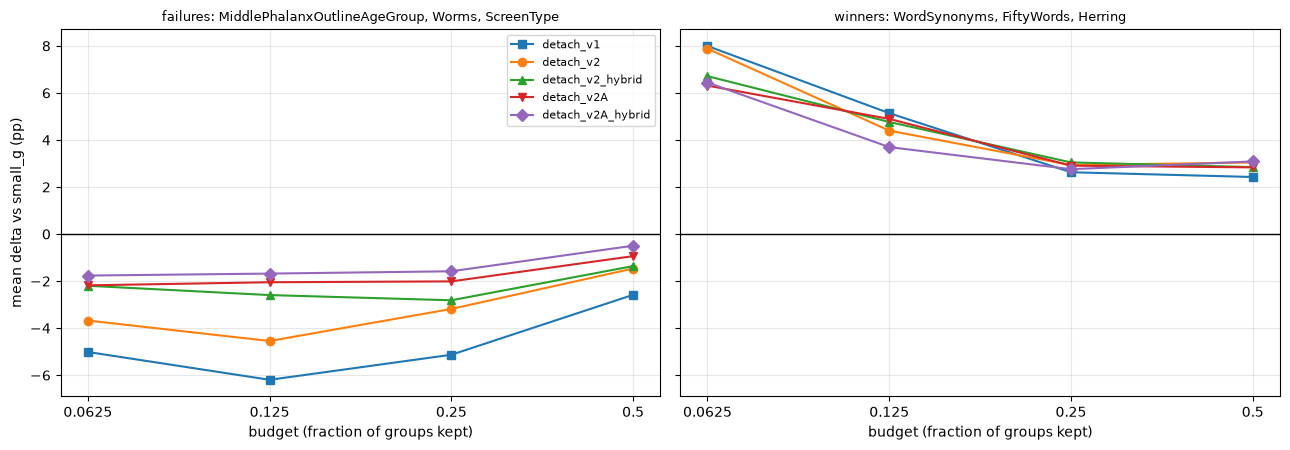

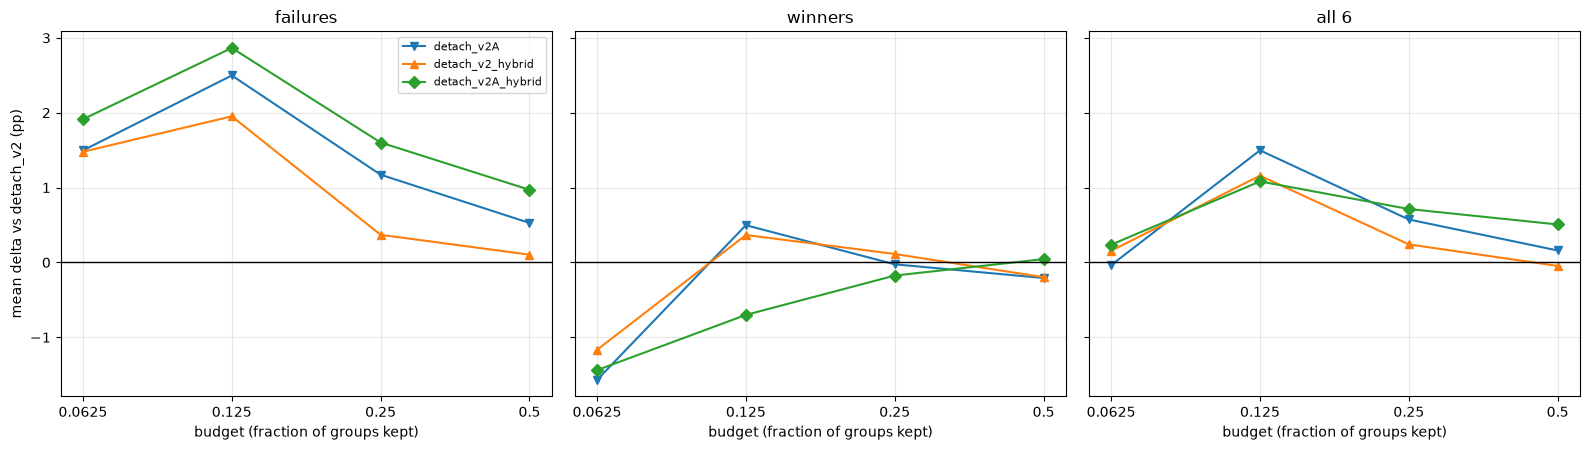

Checks logged in this session:
  PASS: Check 1: dataset lists - 6 datasets, all development, none held out
  PASS: official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g
  PASS: Check 7: detach_v2_path and detach_path take training arrays only (v2 parameters: ['Xtr_scaled', 'ytr', 'group_cols', 'budgets', 'B', 'frac', 'alphas', 'seed_base'])
  PASS: Check 7: hybrid_select takes a ranking and block ids only (no data arrays)
  PASS: Check 4 (synthetic): hybrid gives exactly N, includes the top N//2, >= quota per block, handles the shortfall case, is deterministic, matches an independent implementation; quota = 0 -> global top N
  PASS: pilot Test 1 (all groups kept == official) on ECG200 + Beef
  PASS: pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Beef
  PASS: pilot Test 4 (SparseScaler subset) on ECG200 + Beef
  PASS: pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 (0.8700)
  PASS: Check 2: v2 generalises v1: B

In [28]:
# ---- 9.7 Figures ----
markers = {"detach_v1": "s", "detach_v2": "o", "detach_v2_hybrid": "^", "detach_v2A": "v", "detach_v2A_hybrid": "D"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (label, dss) in zip(axes, [("failures", FAIL_USED), ("winners", WIN_USED)]):
    for m in PRUNED_METHODS:
        if dss:
            ax.plot(BUDGETS, [dpp(m, "small_g", b).reindex(dss).mean() for b in BUDGETS], marker=markers[m], label=m)
    ax.axhline(0, color="black", lw=1)
    ax.set_xscale("log"); ax.set_xticks(BUDGETS, [str(b) for b in BUDGETS]); ax.minorticks_off()
    ax.set_xlabel("budget (fraction of groups kept)"); ax.set_title(f"{label}: {', '.join(dss) or 'none complete'}", fontsize=9)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("mean delta vs small_g (pp)"); axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}delta_vs_small_g.png", dpi=150, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, (label, dss) in zip(axes, [("failures", FAIL_USED), ("winners", WIN_USED), ("all 6", PILOT_USED)]):
    for fx in FIXES:
        if dss:
            ax.plot(BUDGETS, [dpp(fx, "detach_v2", b).reindex(dss).mean() for b in BUDGETS], marker=markers[fx], label=fx)
    ax.axhline(0, color="black", lw=1)
    ax.set_xscale("log"); ax.set_xticks(BUDGETS, [str(b) for b in BUDGETS]); ax.minorticks_off()
    ax.set_xlabel("budget (fraction of groups kept)"); ax.set_title(label); ax.grid(alpha=0.3)
axes[0].set_ylabel("mean delta vs detach_v2 (pp)"); axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}delta_vs_v2.png", dpi=150, bbox_inches="tight")
plt.show()

print("Checks logged in this session:")
for name, res in CHECKS:
    print(f"  {res}: {name}")